# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN CUSTOMER CHURN



# 1. Giới thiệu

Notebook này thực hiện xây dựng, đánh giá và tối ưu các mô hình Machine Learning
nhằm dự đoán khả năng khách hàng rời bỏ dịch vụ (**Customer Churn**).

Ba thuật toán được sử dụng gồm:

- **K-Nearest Neighbors (KNN)**
- **Decision Tree (DT)**
- **Naive Bayes (NB)**

### Mục tiêu

- Xây dựng mô hình baseline cho từng thuật toán.
- Đánh giá hiệu quả mô hình bằng các chỉ số phù hợp.
- Tối ưu siêu tham số nhằm cải thiện hiệu suất dự đoán.
- So sánh mô hình trước và sau khi tối ưu.
- So sánh ba thuật toán và lựa chọn mô hình phù hợp cho bài toán Customer Churn.

### Quy trình thực hiện

**Dữ liệu đã tiền xử lý → Baseline → Đánh giá → Tối ưu → Đánh giá lại → So sánh mô hình**

# 2. Khởi tạo môi trường


Import các thư viện cần thiết cho quá trình xây dựng, đánh giá,
tối ưu và trực quan hóa các mô hình Machine Learning.

In [73]:
# Xử lý dữ liệu
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Trực quan hóa
import matplotlib.pyplot as plt

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model selection
from sklearn.model_selection import (
    StratifiedKFold, 
    cross_validate,
    GridSearchCV,
    train_test_split
)

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 3. Chuẩn bị dữ liệu cho Modeling


Dữ liệu sử dụng trong notebook này được kế thừa từ bước
Data Understanding & Preprocessing của nhóm.

Ở bước trước, dữ liệu đã được:

- Làm sạch và xử lý missing values.
- Chia thành tập train/test bằng stratified sampling.
- Chuẩn hóa các biến số.
- One-Hot Encoding các biến phân loại.
- Fit preprocessing trên tập train và transform tập test.

Notebook này sử dụng trực tiếp các tập dữ liệu đã tiền xử lý
để đảm bảo toàn bộ các mô hình được huấn luyện và đánh giá
trên cùng một dữ liệu.

In [74]:
DATA_DIR = Path("../data")

X_train = np.load(DATA_DIR / "X_train_processed.npy")
X_test = np.load(DATA_DIR / "X_test_processed.npy")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

feature_names = joblib.load(
    DATA_DIR / "feature_names.pkl"
)

class_weight = joblib.load(
    DATA_DIR / "class_weight.pkl"
)

In [75]:
print(f"Kích thước dữ liệu")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

Kích thước dữ liệu
X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634,)
y_test : (1409,)
Number of features: 40


### Nhận xét

Dữ liệu sau tiền xử lý gồm **40 đặc trưng** và được chia thành
**5.634 mẫu huấn luyện** và **1.409 mẫu kiểm thử**.

Phân bố nhãn cho thấy số khách hàng không Churn lớn hơn số khách hàng Churn.
Do đó, ngoài Accuracy, các chỉ số **Precision, Recall và F1-score**
cần được xem xét khi đánh giá mô hình.

In [76]:
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == len(feature_names)

print("Shape alignment OK")

Shape alignment OK


In [77]:
# y_train = y_train.squeeze()
# y_test = y_test.squeeze()

# print("y_train shape:", y_train.shape)
# print("y_test shape :", y_test.shape)

In [78]:
print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

Train labels: [0 1]
Test labels : [0 1]


In [79]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [80]:
print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


# 4. Các hàm đánh giá dùng chung


Để đảm bảo các mô hình được đánh giá theo cùng một quy trình,
các hàm đánh giá được định nghĩa một lần và tái sử dụng cho KNN,
Decision Tree và Naive Bayes.

Các chỉ số chính gồm:

- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ dữ liệu.
- **Precision:** mức độ chính xác của các dự đoán Churn.
- **Recall:** khả năng phát hiện khách hàng thực sự Churn.
- **F1-score:** cân bằng giữa Precision và Recall.
- **Confusion Matrix:** thể hiện số lượng TN, FP, FN và TP.

In [81]:
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    # Tính các metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    # In metrics
    print(f"===== {model_name} =====")
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1-score : {results['F1-score']:.4f}")
    print(f"ROC-AUC  : {results['ROC-AUC']:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return results


def compare_model_metrics(baseline_result, tuned_result):
    metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

    comparison_table = pd.DataFrame({
        "Baseline": [baseline_result[m] for m in metrics],
        "Tuned": [tuned_result[m] for m in metrics]
    }, index=metrics)

    comparison_table["Improvement"] = (
        comparison_table["Tuned"] - comparison_table["Baseline"]
    )

    return comparison_table.round(4)

def compare_confusion_matrix(y_test, y_pred_baseline, y_pred_tuned):
    cm_baseline = confusion_matrix(y_test, y_pred_baseline)
    cm_tuned = confusion_matrix(y_test, y_pred_tuned)

    tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
    tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()

    cm_comparison = pd.DataFrame({
        "Baseline": [tn_b, fp_b, fn_b, tp_b],
        "Tuned": [tn_t, fp_t, fn_t, tp_t]
    }, index=["TN", "FP", "FN", "TP"])

    cm_comparison["Change"] = (
        cm_comparison["Tuned"] - cm_comparison["Baseline"]
    )

    return cm_comparison


def classify_prediction(y_true, y_pred):
    if y_true == 1 and y_pred == 1:
        return "TP"
    elif y_true == 0 and y_pred == 0:
        return "TN"
    elif y_true == 0 and y_pred == 1:
        return "FP"
    else:
        return "FN"
    
    
def threshold_analysis(
    y_true,
    probabilities,
    cost_fn=5,
    cost_fp=1
):
    results = []

    thresholds = np.arange(0.10, 0.91, 0.05)

    for threshold in thresholds:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        total_cost = (
            fn * cost_fn +
            fp * cost_fp
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "Total Cost": total_cost
        })

    return pd.DataFrame(results)

#  5. K-Nearest Neighbors



## 5.1 Tổng quan

KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới
      ↓
① Tính khoảng cách với khách trong train
      ↓
② Tìm K người gần nhất
      ↓
③ Xem họ thuộc class 0 hay 1
      ↓
④ Majority vote
      ↓
Dự đoán Churn / No Churn

### 5.2 KNN Baseline

In [82]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train, y_train); # train

In [83]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

Đánh giá KNN baseline 
| Metric    | Câu hỏi nó trả lời                                          |
| --------- | ----------------------------------------------------------- |
| Accuracy  | Tổng thể model đoán đúng bao nhiêu %?                       |
| Precision | Những người model báo churn, bao nhiêu người thực sự churn? |
| Recall    | Những người thực sự churn, model bắt được bao nhiêu?        |
| F1-score  | Cân bằng Precision và Recall                                |
| ROC-AUC   | Model phân biệt churn và non-churn tốt đến đâu?             |

0.5  → gần như random
0.6  → yếu
0.7  → khá
0.8  → tốt
0.9+ → rất tốt
1.0  → hoàn hảo

## 5.3 Đánh giá Baseline

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332
ROC-AUC  : 0.7821

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


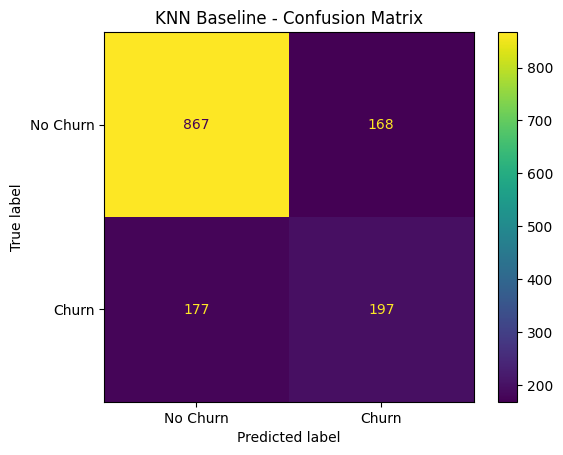

In [84]:
knn_baseline_result = evaluate_model( # danh gia mo hinh 
  y_test, 
  y_predict_knn_baseline, 
  y_proba_km, 
"KNN Baseline") 

1. trong 100 khách -> model dự đoán trúnga 76 khách
2. model cảnh báo 100 khách -> 54 churn thực sự
3. 100 người churn -> model phát hiện được 53 người
4. 
5. yếu

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

---

>  *Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ*

## 5.4 Tối ưu siêu tham số KNN

Hiệu suất của KNN phụ thuộc nhiều vào số lượng láng giềng `k`
(`n_neighbors`). Giá trị `k` quá nhỏ có thể khiến mô hình nhạy với nhiễu,
trong khi giá trị `k` quá lớn có thể làm giảm khả năng phân biệt giữa các lớp.

Trong phần này, **GridSearchCV** được sử dụng để thử nghiệm nhiều giá trị
`n_neighbors` và lựa chọn giá trị tốt nhất thông qua **5-fold cross-validation**.

Do dữ liệu Customer Churn có sự mất cân bằng giữa hai lớp,
**F1-score** được sử dụng làm tiêu chí tối ưu nhằm cân bằng giữa
Precision và Recall.

| 5W1H       | Giải thích                                                                                                                                                                           |
| ---------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **What?**  | **KNN Tuned** là mô hình K-Nearest Neighbors sau khi tối ưu siêu tham số. Trong bài của bạn, tham số được tối ưu là `n_neighbors`, và kết quả tốt nhất là **k = 21**.                |
| **Why?**   | KNN Baseline sử dụng mặc định `k = 5`, nhưng giá trị mặc định chưa chắc phù hợp với dữ liệu Customer Churn. Tuning nhằm tìm `k` giúp mô hình nhận diện Churn tốt hơn.                |
| **When?**  | Thực hiện sau khi đã xây dựng và đánh giá KNN Baseline. Chỉ đánh giá trên `X_test` sau khi quá trình lựa chọn `k` bằng training data hoàn tất.                                       |
| **Where?** | Trong notebook: **5.4 Tối ưu siêu tham số KNN → 5.5 Đánh giá KNN Tuned**.                                                                                                            |
| **Who?**   | `GridSearchCV` thử các giá trị `k`; `KNeighborsClassifier` thực hiện classification; dữ liệu train dùng để tuning và test dùng để đánh giá cuối cùng.                                |
| **How?**   | Thử nhiều `k` → 5-fold CV → tính F1 cho từng cấu hình → chọn `k` tốt nhất → train best model → predict test → đánh giá Accuracy, Precision, Recall, F1, ROC-AUC và Confusion Matrix. |


- K = 5 ? 
- K quá nhỏ -> nhạy với noise -> overfiting 
- K quá lớn -> quá rộng -> mất pattern toàn cục
---
*cần tìm k phù hợp*
--- 
X_train -> Cross-validation -> thử K khác nhau -> chọn best K -> train best model -> X_test <- chỉ đánh giá cuối cùng


In [85]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25]
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train);


In [86]:
print("Best parameters:", grid_knn.best_params_)
print(f"Best CV F1-score: {grid_knn.best_score_:.4f}")

Best parameters: {'n_neighbors': 21}
Best CV F1-score: 0.6047


In [87]:
best_knn = grid_knn.best_estimator_

y_predict_knn_tuned = best_knn.predict(X_test)
y_prob_knn_tuned = best_knn.predict_proba(X_test)[:, 1]

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884
ROC-AUC  : 0.8240

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


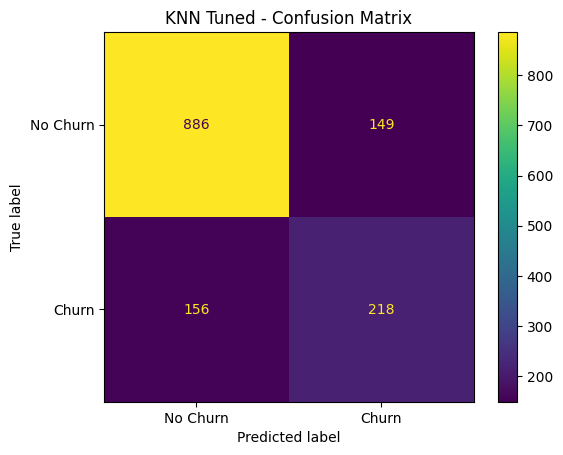

In [88]:
knn_tuned_result = evaluate_model( # danh gia mo hinh 
    y_test,
    y_predict_knn_tuned,
    y_prob_knn_tuned,
    "KNN Tuned"
)

### Nhận xét

Sau khi tối ưu siêu tham số với `n_neighbors = 21`, mô hình KNN đạt:

- **Accuracy = 78.35%**: mô hình dự đoán đúng khoảng 78% khách hàng.
- **Precision = 59.40%**: trong số khách hàng được dự đoán là Churn,
  khoảng 59% thực sự rời bỏ dịch vụ.
- **Recall = 58.29%**: mô hình phát hiện được khoảng 58% khách hàng
  thực sự Churn.
- **F1-score = 58.84%**: cho thấy sự cân bằng giữa Precision và Recall
  đã được cải thiện.
- **ROC-AUC = 82.39%**: mô hình có khả năng phân biệt tương đối tốt
  giữa khách hàng Churn và No Churn.

Từ Confusion Matrix:

- **TN = 886**: dự đoán đúng khách hàng không Churn.
- **FP = 149**: khách hàng không Churn nhưng bị dự đoán là Churn.
- **FN = 156**: khách hàng thực sự Churn nhưng mô hình không phát hiện được.
- **TP = 218**: khách hàng Churn được mô hình phát hiện chính xác.

Mặc dù vẫn còn 156 trường hợp Churn bị bỏ sót, kết quả cho thấy mô hình
KNN sau tối ưu có khả năng nhận diện khách hàng Churn tốt hơn so với
mô hình baseline.

## 5.6 Baseline vs Tuned

In [89]:
knn_metrics_comparison = compare_model_metrics(
    knn_baseline_result,
    knn_tuned_result
)

print("\nKNN Metrics Comparison:")
print(knn_metrics_comparison)


KNN Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7551  0.7835       0.0284
Precision    0.5397  0.5940       0.0543
Recall       0.5267  0.5829       0.0561
F1-score     0.5332  0.5884       0.0552
ROC-AUC      0.7821  0.8240       0.0418


In [90]:
knn_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_knn_baseline,
    y_predict_knn_tuned
)

print("\nKNN Confusion Matrix Comparison:")
print(knn_confusion_comparison)


KNN Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       867    886      19
FP       168    149     -19
FN       177    156     -21
TP       197    218      21


### Kết luận so sánh

KNN Tuned (`k = 21`) cho kết quả tốt hơn KNN Baseline (`k = 5`)
trên toàn bộ các chỉ số đánh giá.

- Accuracy tăng từ **75.51% lên 78.35%**.
- Precision tăng từ **53.97% lên 59.40%**.
- Recall tăng từ **52.67% lên 58.29%**.
- F1-score tăng từ **53.32% lên 58.84%**.
- ROC-AUC tăng từ **78.20% lên 82.39%**.

Đối với lớp Churn, số True Positive tăng từ **197 lên 218**,
trong khi False Negative giảm từ **177 xuống 156**. Như vậy,
mô hình sau tối ưu phát hiện thêm 21 khách hàng Churn và giảm
21 trường hợp Churn bị bỏ sót trên tập test.

Kết quả cho thấy việc tối ưu `n_neighbors` đã cải thiện khả năng
dự đoán của KNN. Vì vậy, KNN Tuned với `k = 21` được chọn làm
phiên bản KNN cuối cùng để so sánh với Decision Tree và Naive Bayes.

# 6. Decision Tree

## 6.1 Tổng quan

### What - DT là gì ?
DT là thuật toán học có giám sát sử dụng cấu trúc dạng cây để đưa ra quyết định dự đoán 
Mỗi nút trong cây thực hiện một điều kiện trên đặc trưng, các nhánh biểu diễn kết quả của điều kiện và các nút lá đưa ra lớp dự đoán cuối cùng

### Why - Tại sao sử dụng DT ?
- Có khả năng mô hình hóa các đặc trưng phi tuyến tính của các đặc trưng
- Ko yêu cầu giả định về phân phối dữ liệu
- Kết quả tương đối dễ giải thích thông qua cấu trúc cây
- Có thể xác định mức độ quan trọng của các đặc trưng
- Phù hợp để so sánh với knn

Tuy nhiên, cây có nguy cơ overfitting nếu cây phát triển quá sâu. Do đó cần thực hiện hyperparmeter tuning.

### When - Khi nào nên áp dụng DT ?
DT phù hợp các bài toán classification khi cần dự đoán nhãn dựa vào các đặc trưng và cần khả năng giải thích quyết định của mô hình

### Where - Được áp dụng ở đâu?
Mô hình được huấn luyện trên 'X_train' và 'y_train'
Mô hình được đánh giá trên 'X_test' và 'y_test'

### Who - Các thành phần tham gia
- `DecisionTreeClassifier`: xây dựng mô hình Decision Tree.
- Training set: dùng để huấn luyện và tối ưu mô hình.
- Test set: dùng để đánh giá mô hình cuối cùng.
- GridSearchCV: được sử dụng ở bước sau để tìm hyperparameter phù hợp.

### How – Decision Tree hoạt động như thế nào?

Decision Tree liên tục chia dữ liệu thành các nhóm dựa trên những đặc trưng
giúp phân biệt các lớp tốt nhất.

Quá trình có thể mô tả:

Data
↓
Chọn feature và điểm chia
↓
Chia dữ liệu thành các nhánh
↓
Tiếp tục chia tại các node con
↓
Leaf Node
↓
Dự đoán No Churn / Churn

Sau khi xây dựng baseline, các hyperparameter như `max_depth` sẽ được
điều chỉnh nhằm kiểm soát độ phức tạp của cây và hạn chế overfitting.

## 6.2 DT Baseline

In [91]:
dt_baseline = DecisionTreeClassifier(random_state=42)

In [92]:
dt_baseline.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

## 6.3 Đánh giá Decision Tree Baseline

Mô hình Decision Tree Baseline được đánh giá trên tập test bằng cùng
hệ thống chỉ số đã sử dụng cho KNN:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Classification Report
- Confusion Matrix

Việc sử dụng cùng phương pháp đánh giá giúp đảm bảo tính nhất quán
khi so sánh các mô hình.

In [93]:
y_predict_dt_baseline = dt_baseline.predict(X_test)
y_prob_dt_baseline =  dt_baseline.predict_proba(X_test)[:,1]

===== Desicion Tree Baseline =====
Accuracy : 0.7211
Precision: 0.4753
Recall   : 0.4893
F1-score : 0.4822
ROC-AUC  : 0.6468

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1035
           1       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409

Confusion Matrix:
[[833 202]
 [191 183]]


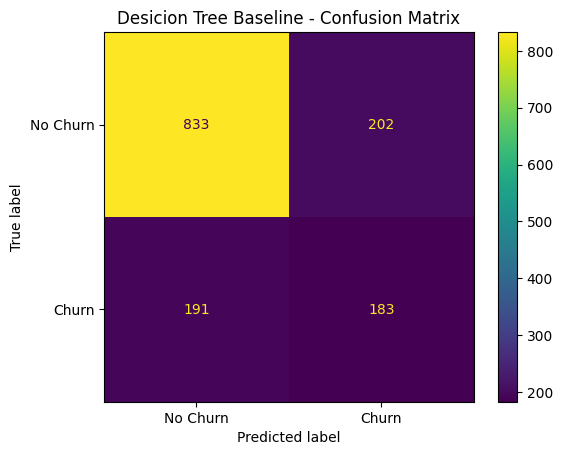

In [94]:
dt_baseline_result = evaluate_model(
  y_test,
  y_predict_dt_baseline,
  y_prob_dt_baseline,
  "Desicion Tree Baseline"
)

### Nhận xét

Decision Tree Baseline đạt:

- **Accuracy = 72.11%**
- **Precision = 47.58%**
- **Recall = 50.00%**
- **F1-score = 48.76%**
- **ROC-AUC = 65.02%**

Confusion Matrix cho thấy mô hình phát hiện đúng **187** khách hàng Churn,
nhưng đồng thời bỏ sót **187** trường hợp Churn (False Negative).

Kết quả baseline cho thấy khả năng nhận diện lớp Churn còn hạn chế.
Đặc biệt, Decision Tree với cấu hình mặc định có thể tạo cây quá phức tạp
do không giới hạn `max_depth`, làm tăng nguy cơ overfitting.

Do đó, bước tiếp theo cần kiểm soát độ phức tạp của cây và tối ưu các
hyperparameter phù hợp trước khi đưa ra kết luận về hiệu quả của
Decision Tree.

## 6.4 Tối ưu siêu tham số Decision Tree

### Decision Tree Tuning

- **What:** Tối ưu các hyperparameter kiểm soát độ phức tạp của Decision Tree.
- **Why:** Decision Tree mặc định có thể phát triển cây quá sâu và học quá sát
  training data, dẫn đến overfitting và khả năng tổng quát hóa kém.
- **When:** Thực hiện sau khi đã xây dựng và đánh giá Decision Tree Baseline.
- **Where:** Việc lựa chọn hyperparameter được thực hiện trên training set
  bằng cross-validation; test set không được sử dụng để lựa chọn tham số.
- **Who:** `GridSearchCV` kết hợp với `DecisionTreeClassifier` để tìm cấu hình
  phù hợp nhất.
- **How:** Thử nhiều tổ hợp hyperparameter bằng 5-fold cross-validation và
  sử dụng F1-score làm tiêu chí lựa chọn mô hình tốt nhất.

max_depth
    → cây được phép sâu bao nhiêu

min_samples_split
    → cần tối thiểu bao nhiêu mẫu để tiếp tục chia node

min_samples_leaf
    → mỗi leaf phải có tối thiểu bao nhiêu mẫu

### Tuning

In [95]:
param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train, y_train);

In [96]:
print("max_depth:", grid_dt.best_estimator_.max_depth)
print("min_samples_leaf:", grid_dt.best_estimator_.min_samples_leaf)
print("min_samples_split:", grid_dt.best_estimator_.min_samples_split)
print("criterion:", grid_dt.best_estimator_.criterion)

max_depth: 5
min_samples_leaf: 10
min_samples_split: 2
criterion: entropy


In [97]:
best_dt = grid_dt.best_estimator_
print(best_dt)

DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=10,
                       random_state=42)


### Kết quả Hyperparameter Tuning

GridSearchCV lựa chọn cấu hình tốt nhất:

- `criterion = entropy`
- `max_depth = 5`
- `min_samples_leaf = 10`
- `min_samples_split = 2`

Kết quả cho thấy trong các cấu hình được thử nghiệm, tiêu chí `entropy`
kết hợp với cây có độ sâu giới hạn được lựa chọn dựa trên F1-score
qua 5-fold cross-validation.

Việc giới hạn `max_depth` và yêu cầu tối thiểu 10 mẫu tại mỗi leaf
giúp kiểm soát độ phức tạp của Decision Tree, trong khi `entropy`
được sử dụng để đánh giá chất lượng của các phép chia node.

## 6.5 DT Tuned

In [98]:
y_predict_dt_tuned = best_dt.predict(X_test)
y_prob_dt_tuned = best_dt.predict_proba(X_test)[:,1]

## 6.6 Baseline vs Tuned

===== Decision Tree Tuned =====
Accuracy : 0.7984
Precision: 0.6347
Recall   : 0.5668
F1-score : 0.5989
ROC-AUC  : 0.8321

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

Confusion Matrix:
[[913 122]
 [162 212]]


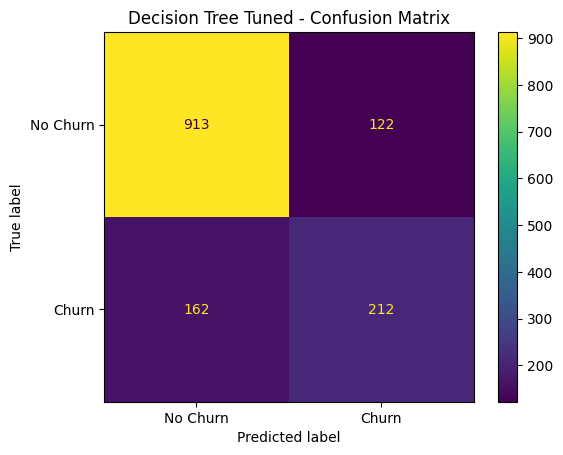

In [99]:
dt_tuned_result = evaluate_model(
  y_test,
  y_predict_dt_tuned,
  y_prob_dt_tuned,
  "Decision Tree Tuned"
)

In [100]:
dt_metrics_comparison = compare_model_metrics(
    dt_baseline_result,
    dt_tuned_result
)

print("\nDecision Tree Metrics Comparison:")
print(dt_metrics_comparison)


Decision Tree Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7211  0.7984       0.0774
Precision    0.4753  0.6347       0.1594
Recall       0.4893  0.5668       0.0775
F1-score     0.4822  0.5989       0.1167
ROC-AUC      0.6468  0.8321       0.1853


In [101]:
dt_confusion_comparison = compare_confusion_matrix(
    y_test, 
    y_predict_dt_baseline,
    y_predict_dt_tuned
)

print("\nDecision Tree Confusion Matrix Comparison:")
print(dt_confusion_comparison)


Decision Tree Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       833    913      80
FP       202    122     -80
FN       191    162     -29
TP       183    212      29


# 7. Naive Bayes


## 7.1 Naive Bayes
1. What
- Naive Bayes (NB) là thuật toán phân loại dựa trên xác suất và định lý Bayes.
- Ví dụ đơn giản, nó xử lý bằng chứng từ Contract, tenure, MonthlyCharges, TechSupport theo giả định độc lập có điều kiện, dù trong thực tế chúng có thể liên quan nhau

2. Why
- Nhanh, đơn giản, ít computational cost và tạo được xác suất dự đoán thông qua predict_proba()
- Khác với các model trên: 
    + KNN → dựa trên khoảng cách giữa các khách hàng
    + Decision Tree → dựa trên các luật chia nhánh
    + Naive Bayes → dựa trên xác suất
- Ba cách tiếp cận classification khác nhau, phù hợp với yêu cầu rubric về so sánh nhiều thuật toán và thảo luận ưu/nhược điểm, mức phù hợp với dữ liệu.

3. When 
- NB thường hữu ích khi cần một classifier nhanh, đơn giản và làm baseline/comparison model, đặc biệt khi số feature tương đối nhiều.

---
- Naive Bayes có nhiều biến thể:
    + GaussianNB
    + MultinomialNB
    + BernoulliNB
    + CategoricalNB
- Với dữ liệu hiện tại có numerical features đã scale + categorical features đã one-hot, chúng ta có thể bắt đầu bằng **GaussianNB** như một lựa chọn thực dụng cho dữ liệu đầu vào hiện tại

## 7.2 Baseline

In [102]:
nb_baseline = GaussianNB()

In [103]:
nb_baseline.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [104]:
y_predict_nb_baseline = nb_baseline.predict(X_test)
y_prob_nb_baseline = nb_baseline.predict_proba(X_test)[:,1]

===== Naive Bayes Baseline =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


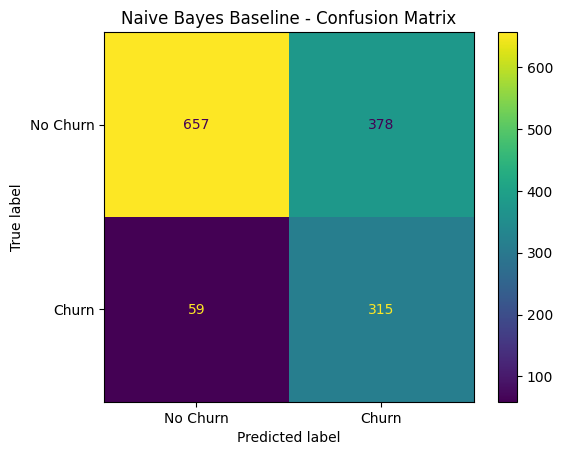

In [105]:
nb_baseline_result = evaluate_model(
    y_test,
    y_predict_nb_baseline,
    y_prob_nb_baseline,
    "Naive Bayes Baseline"
)

### Nhận xét kết quả Baseline

Mô hình Gaussian Naive Bayes Baseline đạt Accuracy = 68.99%, F1-score = 59.04% và ROC-AUC = 80.93%.

Điểm nổi bật của mô hình là Recall đạt 84.22%. Trong tổng số 374 khách hàng thực sự rời bỏ dịch vụ (Churn), mô hình dự đoán đúng 315 khách hàng và chỉ bỏ sót 59 khách hàng (False Negative). Điều này cho thấy mô hình có khả năng phát hiện khách hàng có nguy cơ rời bỏ khá tốt.

Tuy nhiên, Precision chỉ đạt 45.45%. Mô hình dự đoán nhầm 378 khách hàng không Churn thành Churn (False Positive), cho thấy số lượng cảnh báo sai còn tương đối cao.

Nhìn chung, Naive Bayes Baseline có xu hướng ưu tiên phát hiện nhiều khách hàng Churn, giúp giảm số trường hợp bỏ sót khách hàng có nguy cơ rời bỏ, nhưng phải đánh đổi bằng việc gia tăng số lượng False Positive. Trong bối cảnh kinh doanh, điều này có thể giúp doanh nghiệp hạn chế bỏ sót khách hàng cần giữ chân, nhưng đồng thời có thể làm tăng chi phí nếu triển khai chương trình giữ chân cho những khách hàng thực tế không có ý định rời bỏ.

## 7.3 Hyperparameter Tuning

`var_smoothing ?`

GaussianNB giả định giá trị của mỗi feature trong từng class tuân theo phân phối Gaussian. Khi tính xác suất, model sử dụng mean và variance của feature.
Vấn đề là nếu variance của một feature quá nhỏ, việc tính xác suất có thể trở nên không ổn định. var_smoothing thêm một lượng nhỏ vào variance để làm phép tính ổn định hơn.

default của GaussinNB là var_smoothing=1e-9

Sau khi xây dựng mô hình Baseline, `GridSearchCV` được sử dụng để tìm giá trị `var_smoothing` phù hợp cho Gaussian Naive Bayes.

`var_smoothing` giúp ổn định việc ước lượng phương sai trong Gaussian Naive Bayes bằng cách bổ sung một lượng nhỏ vào variance của các đặc trưng.

Quá trình tuning sử dụng 5-fold Cross-Validation (`cv=5`) trên tập training. F1-score được chọn làm tiêu chí đánh giá do dữ liệu Customer Churn bị mất cân bằng và cần cân bằng giữa Precision và Recall.

Tập test không được sử dụng trong quá trình lựa chọn hyperparameter nhằm đảm bảo đánh giá cuối cùng được thực hiện trên dữ liệu chưa được sử dụng để tối ưu mô hình.


In [106]:
param_grid_nb = {
    "var_smoothing": np.logspace(-12, -6, 13)
}

grid_nb = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid_nb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_nb.fit(X_train, y_train);

In [107]:
print("Best Parameters:", grid_nb.best_params_)
print("Best CV F1-score:", round(grid_nb.best_score_, 4))

Best Parameters: {'var_smoothing': np.float64(1e-12)}
Best CV F1-score: 0.5953


## 7.4 Naive Bayes Tuned

In [108]:
best_nb = grid_nb.best_estimator_
print(best_nb)

GaussianNB(var_smoothing=np.float64(1e-12))


In [109]:
y_predict_nb_tuned = best_nb.predict(X_test)
y_prob_nb_tuned = best_nb.predict_proba(X_test)[:,1]

===== Naive Bayes Tuned =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


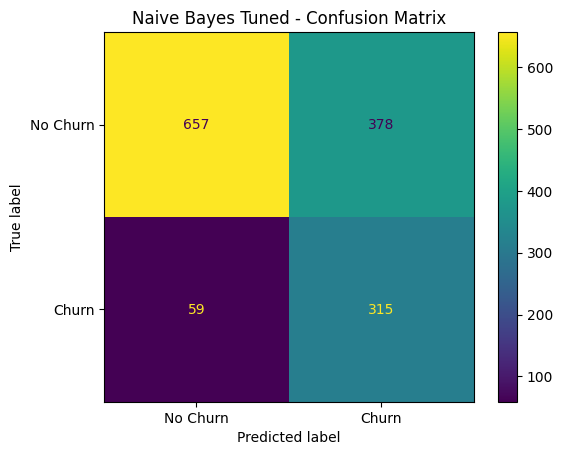

In [110]:
nb_tuned_result = evaluate_model(
    y_test, 
    y_predict_nb_tuned,
    y_prob_nb_tuned,
    "Naive Bayes Tuned"
)

### Nhận xét sau Hyperparameter Tuning

Sau quá trình Hyperparameter Tuning bằng GridSearchCV, giá trị `var_smoothing = 1e-12` được lựa chọn với F1-score trung bình qua 5-fold Cross-Validation đạt 0.5953.

Tuy nhiên, khi đánh giá mô hình đã tuning trên tập test, các chỉ số Accuracy, Precision, Recall, F1-score và ROC-AUC không thay đổi so với mô hình Baseline. Confusion Matrix cũng giữ nguyên với 657 TN, 378 FP, 59 FN và 315 TP.

Kết quả cho thấy việc điều chỉnh `var_smoothing` trong phạm vi khảo sát chưa tạo ra sự cải thiện đáng kể đối với khả năng phân loại của Gaussian Naive Bayes trên tập dữ liệu hiện tại.

Mặc dù vậy, mô hình vẫn duy trì Recall cao ở mức 84.22%, cho thấy khả năng phát hiện phần lớn khách hàng thực sự Churn. Đổi lại, Precision chỉ đạt 45.45% và số lượng False Positive còn cao, thể hiện sự đánh đổi giữa khả năng phát hiện khách hàng Churn và số lượng cảnh báo sai.

In [111]:
nb_metrics_comparison = compare_model_metrics(
    nb_baseline_result,
    nb_tuned_result
)

print("\nNaive Bayes Metrics Comparison:")
print(nb_metrics_comparison)


Naive Bayes Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.6899  0.6899          0.0
Precision    0.4545  0.4545          0.0
Recall       0.8422  0.8422          0.0
F1-score     0.5904  0.5904          0.0
ROC-AUC      0.8093  0.8093          0.0


In [112]:
nb_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_nb_baseline,
    y_predict_nb_tuned
)

print("\nNaive Bayes Confusion Matrix Comparison:")
print(nb_confusion_comparison)


Naive Bayes Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       657    657       0
FP       378    378       0
FN        59     59       0
TP       315    315       0


# 8. Model Evaluation & Compariso

## 8.1 Cross-validation
Sau khi hoàn thành quá trình xây dựng và tuning ba mô hình KNN, Decision Tree và Naive Bayes, Cross-validation được sử dụng để đánh giá hiệu suất và độ ổn định của các mô hình.

Trong phần này, Stratified 5-Fold Cross-Validation được sử dụng trên tập training nhằm duy trì tỷ lệ giữa hai lớp Churn và No Churn trong mỗi fold.

Các mô hình sẽ được đánh giá bằng Precision, Recall, F1-score và ROC-AUC. Kết quả được báo cáo dưới dạng giá trị trung bình (Mean) và độ lệch chuẩn (Standard Deviation - Std) qua 5 folds.

In [113]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("StratifiedKFold CV setup complete.")
print(cv)


StratifiedKFold CV setup complete.
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


n_splits=5 nghĩa là chia training data thành 5 phần

Lần 1: [**TEST**] [TRAIN] [TRAIN] [TRAIN] [TRAIN]

Lần 2: [TRAIN] [**TEST**] [TRAIN] [TRAIN] [TRAIN]

Lần 3: [TRAIN] [TRAIN] [**TEST**] [TRAIN] [TRAIN]

Lần 4: [TRAIN] [TRAIN] [TRAIN] [**TEST**] [TRAIN]

Lần 5: [TRAIN] [TRAIN] [TRAIN] [TRAIN] [**TEST**]

In [114]:
print(f'knn {best_knn}')
print(f'dt {best_dt}')
print(f'nb {best_nb}')

knn KNeighborsClassifier(n_neighbors=21)
dt DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=10,
                       random_state=42)
nb GaussianNB(var_smoothing=np.float64(1e-12))


In [115]:
models = {
    "knn": best_knn,
    "dt": best_dt,
    "nb": best_nb
}

In [116]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [117]:
cv_results = {}

for name, model in models.items():
    score = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )
    cv_results[name] = score
        

In [118]:
print("\nCross-validation results:")
for name, score in cv_results.items():
    print(f"\n{name.upper()} Model:")
    for metric in scoring.keys():
        train_score = np.mean(score[f'train_{metric}'])
        test_score = np.mean(score[f'test_{metric}'])
        print(f"{metric.capitalize()} - Train: {train_score:.4f}, Test: {test_score:.4f}")


Cross-validation results:

KNN Model:
Precision - Train: 0.6514, Test: 0.6131
Recall - Train: 0.6142, Test: 0.5819
F1 - Train: 0.6322, Test: 0.5967
Roc_auc - Train: 0.8609, Test: 0.8291

DT Model:
Precision - Train: 0.6518, Test: 0.6383
Recall - Train: 0.5463, Test: 0.5211
F1 - Train: 0.5918, Test: 0.5713
Roc_auc - Train: 0.8537, Test: 0.8314

NB Model:
Precision - Train: 0.4580, Test: 0.4591
Recall - Train: 0.8488, Test: 0.8475
F1 - Train: 0.5950, Test: 0.5955
Roc_auc - Train: 0.8226, Test: 0.8221


In [119]:
for name, scores in cv_results.items():

    print(f"\n{name} Model:")

    for metric in ["precision", "recall", "f1", "roc_auc"]:

        test_scores = scores[f"test_{metric}"]

        print(
            f"{metric.capitalize():9s}: "
            f"{test_scores.mean():.4f} ± {test_scores.std():.4f}"
        )


knn Model:
Precision: 0.6131 ± 0.0204
Recall   : 0.5819 ± 0.0286
F1       : 0.5967 ± 0.0199
Roc_auc  : 0.8291 ± 0.0102

dt Model:
Precision: 0.6383 ± 0.0241
Recall   : 0.5211 ± 0.0552
F1       : 0.5713 ± 0.0300
Roc_auc  : 0.8314 ± 0.0092

nb Model:
Precision: 0.4591 ± 0.0066
Recall   : 0.8475 ± 0.0208
F1       : 0.5955 ± 0.0081
Roc_auc  : 0.8221 ± 0.0125


### Nhận xét kết quả Cross-validation

Kết quả Stratified 5-Fold Cross-Validation cho thấy ba mô hình có những ưu điểm và hạn chế khác nhau.

**KNN** đạt F1-score trung bình cao nhất với 0.5967 ± 0.0199. Precision đạt 0.6131 và Recall đạt 0.5819, cho thấy mô hình duy trì sự cân bằng tương đối tốt giữa khả năng phát hiện khách hàng Churn và độ chính xác của các dự đoán Churn.

**Decision Tree** đạt Precision cao nhất (0.6383 ± 0.0241) và ROC-AUC cao nhất (0.8314 ± 0.0092). Tuy nhiên, Recall chỉ đạt 0.5211 ± 0.0552 và có độ lệch chuẩn lớn nhất trong ba mô hình ở chỉ số này, cho thấy khả năng phát hiện khách hàng Churn của Decision Tree có sự dao động đáng kể hơn giữa các folds.

**Naive Bayes** đạt Recall cao nhất với 0.8475 ± 0.0208, cho thấy khả năng phát hiện phần lớn khách hàng thực sự Churn. Mô hình cũng có F1-score khá ổn định với 0.5955 ± 0.0081, đây là độ lệch chuẩn F1 thấp nhất trong ba mô hình. Tuy nhiên, Precision chỉ đạt 0.4591, cho thấy mô hình tạo ra tương đối nhiều dự đoán False Positive.

Nhìn chung, chưa có mô hình nào vượt trội hoàn toàn trên tất cả các tiêu chí. KNN đạt F1-score trung bình cao nhất, Decision Tree nổi bật về Precision và ROC-AUC, trong khi Naive Bayes nổi bật về Recall và độ ổn định của F1-score. Vì vậy, việc lựa chọn mô hình cuối cùng chưa được thực hiện tại bước này và cần kết hợp thêm kết quả trên tập test, phân tích lỗi False Positive/False Negative và ý nghĩa kinh doanh.

## 8.2 Model Performance Comparison

Sau khi thực hiện Stratified 5-Fold Cross-Validation, kết quả Cross-validation được kết hợp với kết quả đánh giá trên tập test để so sánh hiệu suất của ba mô hình KNN, Decision Tree và Naive Bayes.

Việc so sánh không chỉ dựa trên một chỉ số duy nhất mà xem xét đồng thời Precision, Recall, F1-score, ROC-AUC và độ ổn định của mô hình qua các folds.

Ở giai đoạn này, mục tiêu là phân tích ưu và nhược điểm của từng mô hình. Mô hình cuối cùng chưa được lựa chọn cho đến khi hoàn thành Error Analysis và phân tích ý nghĩa kinh doanh.

In [120]:
test_comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "Decision Tree",
        "Naive Bayes"
    ],

    "Precision": [
        knn_tuned_result["Precision"],
        dt_tuned_result["Precision"],
        nb_tuned_result["Precision"]
    ],

    "Recall": [
        knn_tuned_result["Recall"],
        dt_tuned_result["Recall"],
        nb_tuned_result["Recall"]
    ],

    "F1-score": [
        knn_tuned_result["F1-score"],
        dt_tuned_result["F1-score"],
        nb_tuned_result["F1-score"]
    ],

    "ROC-AUC": [
        knn_tuned_result["ROC-AUC"],
        dt_tuned_result["ROC-AUC"],
        nb_tuned_result["ROC-AUC"]
    ]
})

test_comparison.round(4)

,Model,Precision,Recall,F1-score,ROC-AUC
0,KNN,0.5940,0.5829,0.5884,0.8240
1,Decision Tree,0.6347,0.5668,0.5989,0.8321
2,Naive Bayes,0.4545,0.8422,0.5904,0.8093


### Nhận xét Model Performance Comparison

Kết quả đánh giá cho thấy không có mô hình nào vượt trội hoàn toàn trên tất cả các tiêu chí.

**Decision Tree** đạt kết quả tốt nhất trên tập test về Precision (0.6347), F1-score (0.5989) và ROC-AUC (0.8321). Đặc biệt, ROC-AUC trên tập test (0.8321) gần với ROC-AUC trung bình qua Cross-validation (0.8314 ± 0.0092), cho thấy khả năng phân biệt hai lớp của mô hình tương đối ổn định. Tuy nhiên, CV F1-score chỉ đạt 0.5713 ± 0.0300 và thấp hơn kết quả trên tập test.

**KNN** đạt F1-score trung bình qua Cross-validation cao nhất (0.5967 ± 0.0199). Kết quả F1-score trên tập test (0.5884) cũng tương đối gần với kết quả Cross-validation, cho thấy hiệu suất khá nhất quán. Tuy nhiên, Precision và ROC-AUC trên tập test vẫn thấp hơn Decision Tree.

**Naive Bayes** nổi bật với Recall trên tập test đạt 0.8422 và F1-score qua Cross-validation đạt 0.5955 ± 0.0081. Độ lệch chuẩn F1-score thấp nhất trong ba mô hình cho thấy hiệu suất F1 khá ổn định giữa các folds. Tuy nhiên, Precision chỉ đạt 0.4545 và ROC-AUC trên tập test đạt 0.8093, thấp nhất trong ba mô hình.

Nhìn chung, Decision Tree hiện có hiệu suất tổng thể tốt trên tập test và khả năng phân biệt hai lớp tốt, KNN thể hiện sự cân bằng tương đối tốt giữa Precision và Recall, trong khi Naive Bayes có ưu thế rõ rệt về khả năng phát hiện khách hàng Churn. Do đó, chưa lựa chọn mô hình cuối cùng tại bước này. Cần tiếp tục phân tích False Positive và False Negative để đánh giá tác động của từng loại sai số trong bối cảnh kinh doanh.

## 8.3 Error Analysis

Bên cạnh các chỉ số Precision, Recall, F1-score và ROC-AUC, việc phân tích các trường hợp dự đoán sai giúp hiểu rõ hơn hành vi của từng mô hình.

Trong bài toán Customer Churn, hai loại lỗi quan trọng là:

- **False Positive (FP):** Khách hàng thực tế không Churn nhưng mô hình dự đoán Churn. Điều này có thể dẫn đến việc doanh nghiệp triển khai các chương trình giữ chân không cần thiết.
- **False Negative (FN):** Khách hàng thực tế Churn nhưng mô hình dự đoán No Churn. Điều này khiến doanh nghiệp có nguy cơ bỏ sót khách hàng cần được giữ chân.

Do đó, Confusion Matrix của ba mô hình tuned được so sánh để đánh giá sự đánh đổi giữa False Positive và False Negative.

In [121]:
cm_knn = confusion_matrix(y_test, y_predict_knn_tuned)
cm_dt = confusion_matrix(y_test, y_predict_dt_tuned)
cm_nb = confusion_matrix(y_test, y_predict_nb_tuned)

tn_knn, fp_knn, fn_knn, tp_knn = cm_knn.ravel()
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

print("KNN:", tn_knn, fp_knn, fn_knn, tp_knn)
print("DT :", tn_dt, fp_dt, fn_dt, tp_dt)
print("NB :", tn_nb, fp_nb, fn_nb, tp_nb)

KNN: 886 149 156 218
DT : 913 122 162 212
NB : 657 378 59 315


In [122]:
error_comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "Decision Tree",
        "Naive Bayes"
    ],

    "TN": [
        tn_knn,
        tn_dt,
        tn_nb
    ],

    "FP": [
        fp_knn,
        fp_dt,
        fp_nb
    ],

    "FN": [
        fn_knn,
        fn_dt,
        fn_nb
    ],

    "TP": [
        tp_knn,
        tp_dt,
        tp_nb
    ]
})

error_comparison

,Model,TN,FP,FN,TP
0,KNN,886,149,156,218
1,Decision Tree,913,122,162,212
2,Naive Bayes,657,378,59,315


### Nhận xét Error Analysis

Kết quả Error Analysis cho thấy ba mô hình có sự đánh đổi rõ rệt giữa False Positive (FP) và False Negative (FN).

**Decision Tree** có số False Positive thấp nhất với 122 trường hợp, cho thấy mô hình ít dự đoán nhầm khách hàng không Churn thành Churn. Tuy nhiên, mô hình có 162 False Negative, cao nhất trong ba mô hình, nghĩa là bỏ sót tương đối nhiều khách hàng thực sự Churn.

**Naive Bayes** thể hiện xu hướng ngược lại. Mô hình chỉ có 59 False Negative và phát hiện đúng 315 khách hàng Churn, cho thấy khả năng hạn chế bỏ sót khách hàng có nguy cơ rời bỏ tốt nhất. Tuy nhiên, số False Positive lên tới 378, cao hơn đáng kể so với hai mô hình còn lại. Điều này có thể dẫn đến nhiều cảnh báo Churn không chính xác.

**KNN** nằm tương đối giữa hai mô hình với 149 False Positive và 156 False Negative. Mô hình không giảm False Negative mạnh như Naive Bayes nhưng tạo ra ít False Positive hơn đáng kể.

Nhìn chung, kết quả cho thấy tồn tại sự đánh đổi giữa việc phát hiện nhiều khách hàng Churn và việc hạn chế cảnh báo sai. Nếu ưu tiên giảm số khách hàng Churn bị bỏ sót, Naive Bayes có lợi thế về False Negative. Ngược lại, Decision Tree có lợi thế khi cần hạn chế False Positive. Vì vậy, cần xem xét chi phí và tác động kinh doanh của hai loại lỗi trước khi lựa chọn mô hình cuối cùng.

## 8.4

In [123]:
# Đọc lại dữ liệu gốc
df_raw = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Xử lý TotalCharges giống bước preprocessing ban đầu
df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"],
    errors="coerce"
)

df_raw["TotalCharges"] = df_raw["TotalCharges"].fillna(0)

# Target
df_raw["Churn"] = df_raw["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Features và target giống notebook preprocessing
X_raw = df_raw.drop(columns=["customerID", "Churn"])
y_raw = df_raw["Churn"]

# Tái tạo chính xác train/test split
_, X_test_raw, _, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    stratify=y_raw,
    random_state=42
)

print("X_test_raw shape :", X_test_raw.shape)
print("X_test shape     :", X_test.shape)
print("y_test_raw shape :", y_test_raw.shape)
print("y_test shape     :", y_test.shape)

X_test_raw shape : (1409, 19)
X_test shape     : (1409, 40)
y_test_raw shape : (1409,)
y_test shape     : (1409,)


In [124]:
import numpy as np

same_target = np.array_equal(
    y_test_raw.to_numpy(),
    np.asarray(y_test).ravel()
)

print("Target order identical:", same_target)

Target order identical: True


In [125]:
X_test_raw.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35


In [126]:
error_analysis = X_test_raw.reset_index(drop=True).copy()

# Thêm nhãn thực tế
error_analysis["Actual_Churn"] = np.asarray(y_test).ravel()

# Thêm prediction của từng model
error_analysis["KNN_Prediction"] = y_predict_knn_tuned
error_analysis["DT_Prediction"] = y_predict_dt_tuned
error_analysis["NB_Prediction"] = y_predict_nb_tuned

# Xác định TP / TN / FP / FN
error_analysis["KNN_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["KNN_Prediction"]
    )
]

error_analysis["DT_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["DT_Prediction"]
    )
]

error_analysis["NB_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["NB_Prediction"]
    )
]

error_analysis.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,KNN_Prediction,DT_Prediction,NB_Prediction,KNN_Result,DT_Result,NB_Result
0,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Credit card (automatic),114.05,8468.20,0,0,0,0,TN,TN,TN
1,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Credit card (automatic),100.15,908.55,0,1,1,1,FP,FP,FP
2,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),78.35,3211.20,0,0,0,0,TN,TN,TN
3,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Electronic check,78.20,1468.75,0,0,1,1,TN,FP,FP
4,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),82.65,5919.35,0,0,0,0,TN,TN,TN


In [127]:
for model in ["KNN", "DT", "NB"]:
    print(f"\n{model}")
    print(
        error_analysis[f"{model}_Result"]
        .value_counts()
    )


KNN
KNN_Result
TN    886
TP    218
FN    156
FP    149
Name: count, dtype: int64

DT
DT_Result
TN    913
TP    212
FN    162
FP    122
Name: count, dtype: int64

NB
NB_Result
TN    657
FP    378
TP    315
FN     59
Name: count, dtype: int64


In [128]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} =====")

    error_numeric = (
        error_analysis
        .groupby(f"{model}_Result")[numeric_features]
        .mean()
        .round(2)
    )

    print(error_numeric.loc[["FP", "FN"]])


===== KNN =====
            tenure  MonthlyCharges  TotalCharges
KNN_Result                                      
FP           17.10           80.67       1497.44
FN           24.55           64.11       2071.62

===== DT =====
           tenure  MonthlyCharges  TotalCharges
DT_Result                                      
FP          10.14           75.55        846.28
FN          27.77           68.46       2371.13

===== NB =====
           tenure  MonthlyCharges  TotalCharges
NB_Result                                      
FP          23.88           72.81       1880.13
FN          30.36           60.34       2670.53


In [129]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} =====")

    for feature in categorical_features:

        print(f"\n{feature}")

        table = pd.crosstab(
            error_analysis.loc[
                error_analysis[f"{model}_Result"].isin(["FP", "FN"]),
                f"{model}_Result"
            ],
            error_analysis.loc[
                error_analysis[f"{model}_Result"].isin(["FP", "FN"]),
                feature
            ],
            normalize="index"
        ) * 100

        print(table.round(1))


===== KNN =====

Contract
Contract    Month-to-month  One year  Two year
KNN_Result                                    
FN                    72.4      21.8       5.8
FP                    96.6       2.7       0.7

InternetService
InternetService   DSL  Fiber optic    No
KNN_Result                              
FN               44.9         39.1  16.0
FP               14.8         85.2   0.0

PaymentMethod
PaymentMethod  Bank transfer (automatic)  Credit card (automatic)  \
KNN_Result                                                          
FN                                  23.7                     17.9   
FP                                  11.4                     10.7   

PaymentMethod  Electronic check  Mailed check  
KNN_Result                                     
FN                         33.3          25.0  
FP                         62.4          15.4  

TechSupport
TechSupport    No  No internet service   Yes
KNN_Result                                  
FN           53.2

In [130]:
def segment_error_rate(data, model, feature):

    rows = []

    for category in data[feature].unique():

        segment = data[data[feature] == category]

        actual_negative = segment[
            segment["Actual_Churn"] == 0
        ]

        actual_positive = segment[
            segment["Actual_Churn"] == 1
        ]

        fp_count = (
            actual_negative[f"{model}_Result"] == "FP"
        ).sum()

        fn_count = (
            actual_positive[f"{model}_Result"] == "FN"
        ).sum()

        fp_rate = (
            fp_count / len(actual_negative)
            if len(actual_negative) > 0 else 0
        )

        fn_rate = (
            fn_count / len(actual_positive)
            if len(actual_positive) > 0 else 0
        )

        rows.append({
            feature: category,

            "Actual No Churn": len(actual_negative),
            "FP": fp_count,
            "FP Rate": fp_rate,

            "Actual Churn": len(actual_positive),
            "FN": fn_count,
            "FN Rate": fn_rate
        })

    return pd.DataFrame(rows)

In [131]:
for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} - Contract =====")

    display(
        segment_error_rate(
            error_analysis,
            model,
            "Contract"
        ).round(4)
    )


===== KNN - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,1,0.0031,9,9,1.0000
1,Month-to-month,444,144,0.3243,329,113,0.3435
2,One year,264,4,0.0152,36,34,0.9444



===== DT - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,0,0.0000,9,9,1.0000
1,Month-to-month,444,122,0.2748,329,117,0.3556
2,One year,264,0,0.0000,36,36,1.0000



===== NB - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,0,0.0000,9,9,1.0000
1,Month-to-month,444,344,0.7748,329,24,0.0729
2,One year,264,34,0.1288,36,26,0.7222


### Phân tích lỗi theo loại hợp đồng (Contract)

Kết quả phân tích theo loại hợp đồng cho thấy sự khác biệt rõ rệt trong hành vi dự đoán của ba mô hình.

Nhóm **Month-to-month** là nhóm đáng chú ý nhất do chiếm phần lớn khách hàng Churn trong tập test (329 trên tổng số 374 khách hàng Churn).

Đối với nhóm này, KNN có False Negative Rate là 34.35% và False Positive Rate là 32.43%. Decision Tree có False Negative Rate tương tự ở mức 35.56%, nhưng False Positive Rate thấp hơn, đạt 27.48%.

Naive Bayes có hành vi khác biệt rõ rệt. Mô hình chỉ bỏ sót 24 trong tổng số 329 khách hàng Month-to-month thực sự Churn, tương ứng False Negative Rate 7.29%. Tuy nhiên, mô hình dự đoán nhầm 344 trong tổng số 444 khách hàng Month-to-month không Churn, tương ứng False Positive Rate 77.48%.

Đối với nhóm One-year và Two-year, cả ba mô hình có False Negative Rate cao. Tuy nhiên, số lượng khách hàng Churn thuộc các nhóm này trong tập test tương đối nhỏ (36 khách One-year và 9 khách Two-year), do đó các tỷ lệ này cần được diễn giải cùng với kích thước mẫu.

Nhìn chung, kết quả cho thấy Naive Bayes có xu hướng dự đoán Churn mạnh đối với nhóm Month-to-month, giúp giảm đáng kể số khách hàng Churn bị bỏ sót nhưng đồng thời tạo ra nhiều False Positive. Decision Tree có xu hướng thận trọng hơn khi dự đoán Churn, giúp hạn chế False Positive nhưng bỏ sót nhiều khách hàng Churn hơn.

In [132]:
business_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

segment_results = []

for model in ["KNN", "DT", "NB"]:

    for feature in business_features:

        result = segment_error_rate(
            error_analysis,
            model,
            feature
        )

        result.insert(0, "Feature", feature)
        result.insert(0, "Model", model)

        # Đổi tên category thành một cột chung
        result = result.rename(
            columns={feature: "Category"}
        )

        segment_results.append(result)

business_error_summary = pd.concat(
    segment_results,
    ignore_index=True
)

business_error_summary.round(4)

,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,KNN,Contract,Two year,327,1,0.0031,9,9,1.0000
1,KNN,Contract,Month-to-month,444,144,0.3243,329,113,0.3435
2,KNN,Contract,One year,264,4,0.0152,36,34,0.9444
3,KNN,InternetService,Fiber optic,361,127,0.3518,252,61,0.2421
4,KNN,InternetService,DSL,387,22,0.0568,97,70,0.7216
5,KNN,InternetService,No,287,0,0.0000,25,25,1.0000
6,KNN,PaymentMethod,Credit card (automatic),258,16,0.0620,51,28,0.5490
7,KNN,PaymentMethod,Electronic check,268,93,0.3470,206,52,0.2524
8,KNN,PaymentMethod,Bank transfer (automatic),243,17,0.0700,57,37,0.6491
9,KNN,PaymentMethod,Mailed check,266,23,0.0865,60,39,0.6500


### Business Interpretation of Model Errors

Phân tích lỗi theo đặc điểm khách hàng cho thấy sự khác biệt rõ rệt trong hành vi của ba mô hình.

KNN và Decision Tree có xu hướng nhận diện Churn tốt hơn ở các nhóm khách hàng có các đặc điểm thường gắn với rủi ro Churn cao trong dữ liệu, chẳng hạn như hợp đồng Month-to-month, sử dụng Fiber optic, thanh toán bằng Electronic check, không sử dụng TechSupport hoặc OnlineSecurity. Tuy nhiên, hai mô hình có False Negative Rate cao hơn ở một số nhóm khác, cho thấy chúng có thể bỏ sót những khách hàng Churn có profile ít điển hình hơn.

Decision Tree đặc biệt có xu hướng dự đoán Churn thận trọng. Điều này giúp mô hình hạn chế False Positive nhưng đồng thời làm tăng nguy cơ bỏ sót khách hàng thực sự Churn.

Naive Bayes thể hiện hành vi ngược lại. Trong các segment có nhiều khách hàng Churn, mô hình đạt False Negative Rate rất thấp. Ví dụ, FN Rate chỉ là 7.29% đối với Month-to-month, 8.33% đối với Fiber optic và 6.80% đối với Electronic check. Tuy nhiên, False Positive Rate tương ứng lại rất cao, lần lượt là 77.48%, 60.39% và 68.28%.

Kết quả cho thấy tồn tại sự đánh đổi rõ ràng giữa việc phát hiện nhiều khách hàng có nguy cơ Churn và việc hạn chế các cảnh báo sai. Vì False Negative có thể dẫn đến bỏ lỡ cơ hội giữ chân một khách hàng thực sự rời dịch vụ, trong khi False Positive có thể dẫn đến chi phí giữ chân không cần thiết, việc lựa chọn mô hình không nên chỉ dựa trên Accuracy hoặc F1-score mà cần xem xét chi phí kinh doanh của hai loại lỗi.

Ngoài ra, các tỷ lệ lỗi cần được diễn giải cùng với kích thước của từng segment. Một số nhóm như Two-year có số lượng khách hàng Churn tương đối nhỏ trong tập test, do đó tỷ lệ FN cao không nhất thiết phản ánh hiệu suất tổng thể của mô hình trên toàn bộ khách hàng.

## 8.5

In [133]:
print("KNN :", best_knn.predict_proba(X_train)[:5, 1])
print("DT  :", best_dt.predict_proba(X_train)[:5, 1])
print("NB  :", best_nb.predict_proba(X_train)[:5, 1])   

KNN : [0.38095238 0.38095238 0.         0.0952381  0.42857143]
DT  : [0.38461538 0.37134503 0.01267427 0.01267427 0.52112676]
NB  : [9.99766983e-01 9.98519755e-01 9.19164198e-12 5.35454713e-08
 9.99972172e-01]


### 8.5.1

In [134]:
from sklearn.model_selection import cross_val_predict

oof_prob_knn = cross_val_predict(
    best_knn,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_prob_dt = cross_val_predict(
    best_dt,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_prob_nb = cross_val_predict(
    best_nb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("KNN:", oof_prob_knn[:5])
print("DT :", oof_prob_dt[:5])
print("NB :", oof_prob_nb[:5])

print("\nShapes:")
print(oof_prob_knn.shape)
print(oof_prob_dt.shape)
print(oof_prob_nb.shape)

KNN: [0.57142857 0.42857143 0.04761905 0.0952381  0.57142857]
DT : [0.13812155 0.55925926 0.         0.         0.49344978]
NB : [9.99755294e-01 9.98517964e-01 5.95767764e-12 3.12010079e-08
 9.99971721e-01]

Shapes:
(5634,)
(5634,)
(5634,)


In [135]:
oof_models = {
    "KNN": oof_prob_knn,
    "DT": oof_prob_dt,
    "NB": oof_prob_nb
}

cost_scenarios = [1, 2, 5, 10]

all_cost_sensitivity = []

for model_name, probabilities in oof_models.items():

    for cost_fn in cost_scenarios:

        results = threshold_analysis(
            y_train,
            probabilities,
            cost_fn=cost_fn,
            cost_fp=1
        )

        best_row = results.loc[
            results["Total Cost"].idxmin()
        ]

        all_cost_sensitivity.append({
            "Model": model_name,
            "FN:FP Cost Ratio": f"{cost_fn}:1",
            "Best Threshold": best_row["Threshold"],
            "FP": int(best_row["FP"]),
            "FN": int(best_row["FN"]),
            "Precision": best_row["Precision"],
            "Recall": best_row["Recall"],
            "F1": best_row["F1"],
            "Minimum Cost": best_row["Total Cost"]
        })

cost_sensitivity_table = pd.DataFrame(
    all_cost_sensitivity
)

display(
    cost_sensitivity_table.round(4)
)

,Model,FN:FP Cost Ratio,Best Threshold,FP,FN,Precision,Recall,F1,Minimum Cost
0,KNN,1:1,0.55,441,725,0.6358,0.5151,0.5691,1166.0
1,KNN,2:1,0.40,829,456,0.5562,0.6950,0.6179,1741.0
2,KNN,5:1,0.20,1654,191,0.4408,0.8722,0.5857,2609.0
3,KNN,10:1,0.10,2216,86,0.3887,0.9425,0.5504,3076.0
4,DT,1:1,0.50,446,716,0.6359,0.5211,0.5728,1162.0
5,DT,2:1,0.35,940,390,0.5403,0.7391,0.6243,1720.0
6,DT,5:1,0.15,1825,137,0.4266,0.9084,0.5806,2510.0
7,DT,10:1,0.10,2149,95,0.3945,0.9365,0.5551,3099.0
8,NB,1:1,0.90,1345,255,0.4797,0.8294,0.6078,1600.0
9,NB,2:1,0.90,1345,255,0.4797,0.8294,0.6078,1855.0


In [136]:
def threshold_analysis(
    y_true,
    probabilities,
    cost_fn=5,
    cost_fp=1
):
    results = []

    thresholds = np.arange(0.01, 1.00, 0.01)

    for threshold in thresholds:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        total_cost = (
            fn * cost_fn +
            fp * cost_fp
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "Total Cost": total_cost
        })

    return pd.DataFrame(results)

In [137]:
# Probability trên TEST SET
test_prob_knn = best_knn.predict_proba(X_test)[:, 1]
test_prob_dt  = best_dt.predict_proba(X_test)[:, 1]
test_prob_nb  = best_nb.predict_proba(X_test)[:, 1]

# Threshold đã được chọn từ OOF TRAIN
locked_thresholds = {
    "KNN": 0.20,
    "DT": 0.14,
    "NB": 0.89
}

test_probabilities = {
    "KNN": test_prob_knn,
    "DT": test_prob_dt,
    "NB": test_prob_nb
}

In [138]:
cost_fn = 5
cost_fp = 1

threshold_test_results = []

for model_name, probabilities in test_probabilities.items():

    threshold = locked_thresholds[model_name]

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    total_cost = (
        fn * cost_fn +
        fp * cost_fp
    )

    threshold_test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "Total Cost": total_cost
    })

threshold_test_results = pd.DataFrame(
    threshold_test_results
)

display(
    threshold_test_results.round(4)
)

,Model,Threshold,TN,FP,FN,TP,Precision,Recall,F1,ROC-AUC,Total Cost
0,KNN,0.20,615,420,41,333,0.4422,0.8904,0.5909,0.8240,625
1,DT,0.14,584,451,39,335,0.4262,0.8957,0.5776,0.8321,646
2,NB,0.89,695,340,68,306,0.4737,0.8182,0.6000,0.8093,680


In [139]:
comparison_rows = []

for model_name, probabilities in test_probabilities.items():

    for setting, threshold in [
        ("Default", 0.50),
        ("Cost-sensitive", locked_thresholds[model_name])
    ]:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred
        ).ravel()

        total_cost = fp + 5 * fn

        comparison_rows.append({
            "Model": model_name,
            "Setting": setting,
            "Threshold": threshold,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "Cost (5:1)": total_cost
        })

default_vs_cost = pd.DataFrame(comparison_rows)

display(default_vs_cost.round(4))

,Model,Setting,Threshold,FP,FN,TP,Precision,Recall,F1,Cost (5:1)
0,KNN,Default,0.50,149,156,218,0.5940,0.5829,0.5884,929
1,KNN,Cost-sensitive,0.20,420,41,333,0.4422,0.8904,0.5909,625
2,DT,Default,0.50,122,162,212,0.6347,0.5668,0.5989,932
3,DT,Cost-sensitive,0.14,451,39,335,0.4262,0.8957,0.5776,646
4,NB,Default,0.50,378,59,315,0.4545,0.8422,0.5904,673
5,NB,Cost-sensitive,0.89,340,68,306,0.4737,0.8182,0.6000,680


### 8.5 Cost-sensitive Threshold Analysis

Trong bài toán Customer Churn, hai loại lỗi FP và FN có ý nghĩa kinh doanh khác nhau:

- **False Positive (FP):** khách hàng thực tế không churn nhưng được dự đoán churn. 
  Doanh nghiệp có thể triển khai chính sách giữ chân không cần thiết, làm phát sinh chi phí.
- **False Negative (FN):** khách hàng thực tế churn nhưng được dự đoán không churn.
  Doanh nghiệp có thể bỏ lỡ cơ hội giữ chân khách hàng.

Decision threshold mặc định 0.5 không nhất thiết phù hợp với mọi mục tiêu kinh doanh.
Do đó, nhóm thực hiện cost-sensitive threshold analysis bằng cách giả định các tỷ lệ chi phí
FN:FP khác nhau (1:1, 2:1, 5:1 và 10:1).

Do dataset không cung cấp chi phí kinh doanh thực tế, các tỷ lệ trên chỉ được sử dụng như
các kịch bản phân tích độ nhạy (sensitivity analysis), không đại diện cho chi phí thực tế
của doanh nghiệp.

Threshold được lựa chọn dựa trên out-of-fold predictions của training set nhằm hạn chế
việc sử dụng test set trong quá trình lựa chọn. Với kịch bản minh họa FN:FP = 5:1,
các threshold được chọn là:

- KNN: 0.20
- Decision Tree: 0.14
- Naive Bayes: 0.89

Khi áp dụng các threshold đã khóa lên test set:

- KNN giảm FN từ 156 xuống 41, trong khi FP tăng từ 149 lên 420.
  Tổng relative cost giảm từ 929 xuống 625, tương đương khoảng 32.7%.
- Decision Tree giảm FN từ 162 xuống 39, trong khi FP tăng từ 122 lên 451.
  Tổng relative cost giảm từ 932 xuống 646, tương đương khoảng 30.7%.
- Naive Bayes có relative cost tăng nhẹ từ 673 lên 680. Điều này cho thấy threshold
  được tối ưu trên training data không đảm bảo sẽ cải thiện kết quả trên dữ liệu chưa thấy.

Kết quả cho thấy việc lựa chọn decision threshold phụ thuộc vào mục tiêu kinh doanh
và mức độ nghiêm trọng tương đối của FP và FN. Trong kịch bản FN:FP = 5:1,
KNN với threshold 0.20 đạt relative cost thấp nhất trên test set (625 cost units).
Tuy nhiên, kết quả này không có nghĩa KNN là mô hình tốt nhất trong mọi kịch bản,
vì lựa chọn cuối cùng còn phụ thuộc vào mục tiêu và chi phí thực tế của doanh nghiệp.

### 8.6 Driver-based Insight Analysis

Decision Tree Tuned được lựa chọn làm mô hình đại diện cho driver-based analysis
do mô hình cung cấp feature importance trực tiếp và có cấu trúc quyết định dễ diễn giải.

Việc lựa chọn Decision Tree trong phần này nhằm phục vụ mục tiêu explainability,
không hàm ý Decision Tree là mô hình dự đoán tốt nhất trong mọi tiêu chí.

KNN và Naive Bayes vẫn được sử dụng trong phần đánh giá và so sánh hiệu năng mô hình.

Sau khi đánh giá hiệu năng dự đoán và phân tích decision threshold, bước tiếp theo
là xác định những đặc trưng có vai trò quan trọng trong việc dự đoán Customer Churn.

Trong phần này, Decision Tree Tuned được sử dụng để phân tích feature importance
vì mô hình cung cấp trực tiếp mức độ đóng góp tương đối của từng feature thông qua
thuộc tính `feature_importances_`.

Phân tích này nhằm:

- Xác định các feature được Decision Tree sử dụng nhiều nhất trong quá trình phân loại.
- Tìm các nhóm đặc trưng có liên quan mạnh đến dự đoán churn.
- Chuyển kết quả mô hình thành các insight có thể hỗ trợ quyết định giữ chân khách hàng.

Lưu ý rằng feature importance phản ánh mức độ feature được mô hình sử dụng để dự đoán,
không chứng minh quan hệ nhân quả giữa feature và hành vi churn.

In [140]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# X_raw đã bỏ customerID và Churn
cat_cols = X_raw.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = X_raw.select_dtypes(exclude="object").columns.tolist()

preprocessor_rebuild = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OneHotEncoder(
                drop="if_binary",
                handle_unknown="ignore"
            ),
            cat_cols
        )
    ]
)

preprocessor_rebuild.fit(X_raw)

feature_names = preprocessor_rebuild.get_feature_names_out()

print("Feature names :", len(feature_names))
print("DT importances:", len(best_dt.feature_importances_))

Feature names : 40
DT importances: 40


#### 8.6.1 Feature Importance from Tuned Decision Tree

Decision Tree Tuned được sử dụng để phân tích mức độ quan trọng của các đặc trưng.

Feature importance của Decision Tree phản ánh mức độ mỗi feature đóng góp vào việc
giảm impurity trong quá trình xây dựng cây. Feature có importance cao hơn được mô hình
sử dụng nhiều hơn trong các quyết định phân loại.

Phân tích này được sử dụng để xác định các churn drivers tiềm năng phục vụ bước
phân tích nghiệp vụ tiếp theo.

Lưu ý: Feature importance thể hiện mức độ quan trọng đối với dự đoán của mô hình,
không chứng minh quan hệ nhân quả và cũng không trực tiếp cho biết feature làm tăng
hay giảm xác suất churn.

In [141]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_dt.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance_df.head(10)

,Feature,Importance
0,cat__Contract_Month-to-month,0.535972
1,num__tenure,0.137074
2,cat__InternetService_Fiber optic,0.123477
3,num__MonthlyCharges,0.076155
4,num__TotalCharges,0.030542
5,cat__PaymentMethod_Electronic check,0.024749
6,cat__Contract_One year,0.021193
7,cat__TechSupport_No,0.016027
8,cat__OnlineSecurity_No,0.009699
9,cat__OnlineBackup_No,0.008237


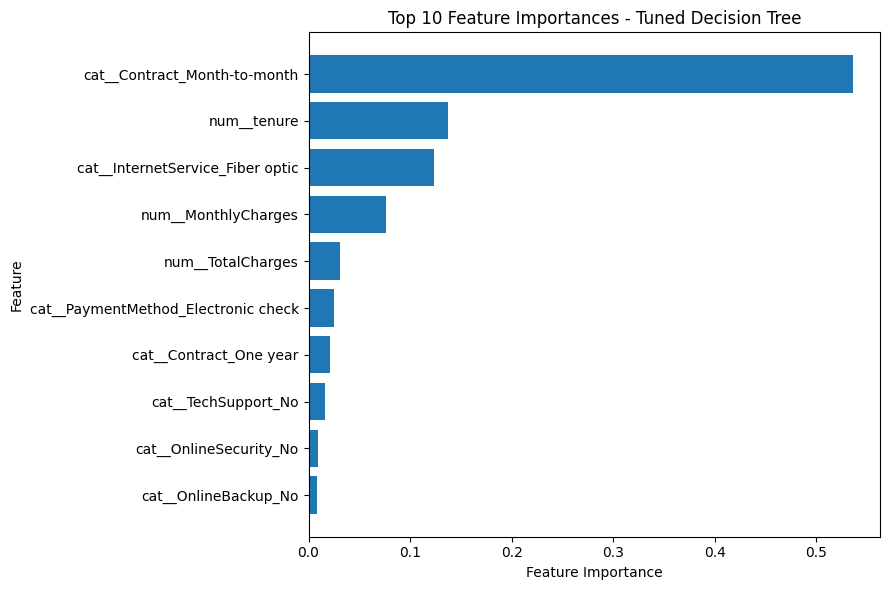

In [142]:
top_10_features = (
    feature_importance_df
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Tuned Decision Tree")

plt.tight_layout()
plt.show()

#### 8.6.2 Top Churn Drivers and Direction of Association

Feature importance cho biết mức độ Decision Tree sử dụng từng đặc trưng trong quá trình
phân loại, nhưng không cho biết đặc trưng đó liên quan với churn theo hướng nào.

Do đó, đối với các feature quan trọng nhất, nhóm tiếp tục đối chiếu với dữ liệu gốc để
xem xét churn rate theo từng nhóm hoặc theo mức giá trị của feature.

Mục tiêu của bước này là kết hợp:

Feature Importance → Direction of Association → Business Interpretation

Phân tích này mang tính mô tả và giải thích hành vi của mô hình, không được diễn giải
như bằng chứng về quan hệ nhân quả.

In [143]:
driver_df = df.copy()

driver_df["Churn_binary"] = (
    driver_df["Churn"]
    .map({"No": 0, "Yes": 1})
)

print(driver_df["Churn_binary"].value_counts())

NameError: name 'df' is not defined

In [ ]:
contract_churn = (
    driver_df
    .groupby("Contract")["Churn_binary"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Churn_Rate",
        "count": "Customers"
    })
    .sort_values("Churn_Rate", ascending=False)
)

contract_churn["Churn_Rate"] *= 100

contract_churn.round(2)

,Churn_Rate,Customers
Contract,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


In [ ]:
internet_churn = (
    driver_df
    .groupby("InternetService")["Churn_binary"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Churn_Rate",
        "count": "Customers"
    })
    .sort_values("Churn_Rate", ascending=False)
)

internet_churn["Churn_Rate"] *= 100

internet_churn.round(2)

,Churn_Rate,Customers
InternetService,,
Fiber optic,41.89,3096
DSL,18.96,2421
No,7.40,1526


In [ ]:
driver_df["Tenure_Group"] = pd.cut(
    driver_df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

tenure_churn = (
    driver_df
    .groupby("Tenure_Group", observed=True)["Churn_binary"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Churn_Rate",
        "count": "Customers"
    })
)

tenure_churn["Churn_Rate"] *= 100

tenure_churn.round(2)

,Churn_Rate,Customers
Tenure_Group,,
0-12 months,47.44,2186
13-24 months,28.71,1024
25-48 months,20.39,1594
49-72 months,9.51,2239


In [ ]:
driver_df["MonthlyCharges_Group"] = pd.qcut(
    driver_df["MonthlyCharges"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ]
)

monthly_churn = (
    driver_df
    .groupby(
        "MonthlyCharges_Group",
        observed=True
    )["Churn_binary"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Churn_Rate",
        "count": "Customers"
    })
)

monthly_churn["Churn_Rate"] *= 100

monthly_churn.round(2)

,Churn_Rate,Customers
MonthlyCharges_Group,,
Q1 - Lowest,11.24,1762
Q2,24.58,1766
Q3,37.51,1757
Q4 - Highest,32.88,1758


| Driver                        | DT Importance | Quan sát từ dữ liệu                                              |
| ----------------------------- | ------------: | ---------------------------------------------------------------- |
| Contract – Month-to-month     |        0.5360 | Month-to-month churn **42.71%**, One year 11.27%, Two year 2.83% |
| tenure                        |        0.1371 | 0–12 tháng **47.44%** → 49–72 tháng chỉ **9.51%**                |
| InternetService – Fiber optic |        0.1235 | Fiber optic **41.89%**, DSL 18.96%, No Internet 7.40%            |
| MonthlyCharges                |        0.0762 | Q1 11.24%, Q2 24.58%, **Q3 37.51%**, Q4 32.88%                   |


#### 8.6.3 Driver-based Insights & Business Interpretation

Kết quả feature importance của Decision Tree Tuned cho thấy bốn đặc trưng nổi bật
nhất gồm Contract_Month-to-month, tenure, InternetService_Fiber optic và
MonthlyCharges. Để xác định hướng của các mối liên hệ, nhóm tiếp tục đối chiếu
feature importance với churn rate quan sát được trên dữ liệu gốc.

**1. Contract type**

`Contract_Month-to-month` là feature có importance cao nhất trong Decision Tree
(0.5360). Khách hàng sử dụng hợp đồng Month-to-month có churn rate 42.71%,
cao hơn đáng kể so với One year (11.27%) và Two year (2.83%).

Kết quả cho thấy nhóm khách hàng sử dụng hợp đồng ngắn hạn là một phân khúc
có rủi ro churn đáng chú ý. Trong thực tế, doanh nghiệp có thể cân nhắc các chương
trình khuyến khích khách hàng phù hợp chuyển sang hợp đồng dài hạn, chẳng hạn
ưu đãi gia hạn hoặc loyalty benefits.

**2. Customer tenure**

`tenure` là feature quan trọng thứ hai (importance = 0.1371). Churn rate giảm rõ
rệt khi thời gian gắn bó tăng: khách hàng trong 0–12 tháng có churn rate 47.44%,
trong khi nhóm 49–72 tháng chỉ còn 9.51%.

Điều này cho thấy khách hàng mới là nhóm cần được chú ý trong chiến lược retention.
Doanh nghiệp có thể ưu tiên onboarding, hỗ trợ và các hoạt động chăm sóc trong
những tháng đầu của vòng đời khách hàng.

**3. Internet service**

`InternetService_Fiber optic` đứng thứ ba về feature importance (0.1235).
Nhóm sử dụng Fiber optic có churn rate 41.89%, so với 18.96% ở DSL và
7.40% ở nhóm không sử dụng Internet Service.

Kết quả xác định khách hàng Fiber optic là một phân khúc có churn rate quan sát
được tương đối cao. Tuy nhiên, phân tích hiện tại chưa xác định nguyên nhân của
sự khác biệt này. Doanh nghiệp có thể xem đây là nhóm cần điều tra thêm về
chất lượng dịch vụ, giá, hỗ trợ kỹ thuật hoặc các yếu tố liên quan trước khi đưa
ra chính sách cụ thể.

**4. Monthly charges**

`MonthlyCharges` có importance = 0.0762. Churn rate tăng từ 11.24% ở quartile
thấp nhất lên 24.58% ở Q2 và đạt 37.51% ở Q3, nhưng giảm nhẹ xuống 32.88%
ở quartile cao nhất.

Do đó, dữ liệu không hỗ trợ kết luận đơn giản rằng MonthlyCharges càng cao thì
churn càng tăng. Thay vào đó, mức phí hàng tháng có mối liên hệ phi tuyến với
churn và có thể tương tác với các yếu tố khác như loại hợp đồng hoặc loại dịch vụ.

**Business interpretation**

Nhìn chung, Decision Tree tập trung phần lớn vào loại hợp đồng, thời gian gắn bó,
loại dịch vụ Internet và mức phí hàng tháng khi dự đoán churn. Kết hợp với churn
rate quan sát được, kết quả gợi ý rằng nhóm khách hàng hợp đồng Month-to-month,
khách hàng mới và khách hàng Fiber optic là những phân khúc đáng được doanh
nghiệp theo dõi trong chiến lược retention.

Các kết quả trên phản ánh association trong dataset và hành vi của mô hình,
không chứng minh rằng các đặc trưng này trực tiếp gây ra churn.

## 8.7 Risk x Value Segmentation

### 8.1 Idea

Sau khi xác định các churn drivers, nhóm tiếp tục phân tích cách doanh nghiệp có thể
ưu tiên khách hàng khi nguồn lực retention có giới hạn.

Chỉ xác suất churn chưa đủ để xác định mức độ ưu tiên. Hai khách hàng có cùng nguy
cơ churn có thể mang lại giá trị kinh doanh khác nhau.

Do dataset không cung cấp Customer Lifetime Value (CLV) hoặc lợi nhuận thực tế,
`MonthlyCharges` được sử dụng như một proxy đơn giản cho giá trị hiện tại của
khách hàng.

Phân tích kết hợp hai chiều:

- Risk: xác suất churn do mô hình dự đoán.
- Value: MonthlyCharges của khách hàng.

Từ đó khách hàng được phân thành bốn nhóm Risk × Value để hỗ trợ việc xác định
mức độ ưu tiên cho các hoạt động retention.

Lưu ý rằng MonthlyCharges chỉ là proxy cho customer value và không đại diện cho
CLV hoặc lợi nhuận thực tế.

### 8.2 Model

Ta dùng Decision Tree như một minh họa segmentation nhất quán với 8.6, và ghi rõ đây là model dùng cho phân tích minh họa chứ chưa phải tuyên bố deployment model cuối cùng.

### 8.3 

In [ ]:
from sklearn.model_selection import train_test_split

X_rv = driver_df.drop(
    columns=[
        "customerID",
        "Churn",
        "Churn_binary",
        "Tenure_Group",
        "MonthlyCharges_Group"
    ],
    errors="ignore"
)

y_rv = driver_df["Churn_binary"]

X_train_rv, X_test_rv, y_train_rv, y_test_rv = train_test_split(
    X_rv,
    y_rv,
    test_size=0.2,
    stratify=y_rv,
    random_state=42
)

print(X_train_rv.shape)
print(X_test_rv.shape)

(5634, 19)
(1409, 19)


In [ ]:
risk_value_df = X_test_rv.copy()
risk_value_df["Churn_Probability"] = test_prob_dt

In [ ]:
value_threshold = X_train_rv["MonthlyCharges"].median()

print(
    "Value threshold (training median):",
    round(value_threshold, 2)
)

Value threshold (training median): 70.5


`Value threshold = 70.5: MonthlyCharges ≥ 70.5 → High Value`

In [ ]:
risk_threshold = np.median(oof_prob_dt)

print(
    "Risk threshold (OOF median probability):",
    round(risk_threshold, 4)
)

Risk threshold (OOF median probability): 0.1935


`Risk threshold = 0.1935: P(churn) ≥ 0.1935 → High Risk.`

In [ ]:
risk_value_df["Risk_Level"] = np.where(
    risk_value_df["Churn_Probability"] >= risk_threshold,
    "High Risk",
    "Low Risk"
)

risk_value_df["Value_Level"] = np.where(
    risk_value_df["MonthlyCharges"] >= value_threshold,
    "High Value",
    "Low Value"
)

risk_value_df["Segment"] = (
    risk_value_df["Risk_Level"]
    + " × "
    + risk_value_df["Value_Level"]
)

risk_value_df[
    [
        "MonthlyCharges",
        "Churn_Probability",
        "Risk_Level",
        "Value_Level",
        "Segment"
    ]
].head(10)

,MonthlyCharges,Churn_Probability,Risk_Level,Value_Level,Segment
437,114.05,0.037736,Low Risk,High Value,Low Risk × High Value
2280,100.15,0.721393,High Risk,High Value,High Risk × High Value
2235,78.35,0.061281,Low Risk,High Value,Low Risk × High Value
4460,78.20,0.567857,High Risk,High Value,High Risk × High Value
3761,82.65,0.000000,Low Risk,High Value,Low Risk × High Value
5748,99.85,0.371345,High Risk,High Value,High Risk × High Value
3568,99.15,0.371345,High Risk,High Value,High Risk × High Value
2976,24.10,0.116402,Low Risk,Low Value,Low Risk × Low Value
5928,19.75,0.012674,Low Risk,Low Value,Low Risk × Low Value
1639,45.05,0.384615,High Risk,Low Value,High Risk × Low Value


Hai người đều trả phí cao nhưng mức độ churn risk hoàn toàn khác nhau. Đây chính là giá trị của segmentation.

In [ ]:
segment_summary = (
    risk_value_df
    .groupby("Segment")
    .agg(
        Customers=("Churn_Probability", "size"),
        Avg_Churn_Probability=("Churn_Probability", "mean"),
        Avg_MonthlyCharges=("MonthlyCharges", "mean")
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / len(risk_value_df)
    * 100
)

segment_summary = segment_summary[
    [
        "Segment",
        "Customers",
        "Customer_Percentage",
        "Avg_Churn_Probability",
        "Avg_MonthlyCharges"
    ]
]

segment_summary.round(3)

,Segment,Customers,Customer_Percentage,Avg_Churn_Probability,Avg_MonthlyCharges
0,High Risk × High Value,434,30.802,0.510,89.509
1,High Risk × Low Value,262,18.595,0.391,45.515
2,Low Risk × High Value,246,17.459,0.080,91.800
3,Low Risk × Low Value,467,33.144,0.059,36.288


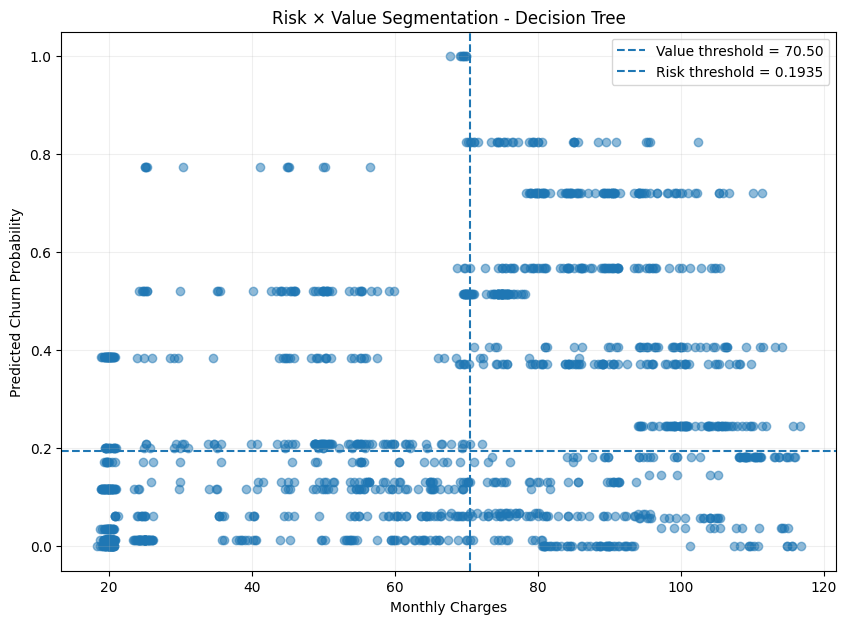

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    risk_value_df["MonthlyCharges"],
    risk_value_df["Churn_Probability"],
    alpha=0.5
)

# Value threshold
plt.axvline(
    x=value_threshold,
    linestyle="--",
    label=f"Value threshold = {value_threshold:.2f}"
)

# Risk threshold
plt.axhline(
    y=risk_threshold,
    linestyle="--",
    label=f"Risk threshold = {risk_threshold:.4f}"
)

plt.xlabel("Monthly Charges")
plt.ylabel("Predicted Churn Probability")
plt.title("Risk × Value Segmentation - Decision Tree")

plt.legend()
plt.grid(alpha=0.2)
plt.show()

#### 8.7.6 Business Interpretation

Risk × Value segmentation được xây dựng bằng cách kết hợp xác suất churn dự đoán
từ Decision Tree với MonthlyCharges, được sử dụng như một proxy đơn giản cho
customer value.

Để hạn chế việc lựa chọn ngưỡng dựa trên test set, các cutoff được xác định từ
training data. High Value được xác định khi MonthlyCharges >= 70.50, tương ứng
với median của training set. High Risk được xác định khi predicted churn
probability >= 0.1935, tương ứng với median của out-of-fold churn probabilities
trên training set.

Kết quả trên 1,409 khách hàng trong test set:

- High Risk × High Value: 434 khách hàng (30.80%), với churn probability trung
  bình 0.510 và MonthlyCharges trung bình 89.51.
- High Risk × Low Value: 262 khách hàng (18.59%), với churn probability trung
  bình 0.391 và MonthlyCharges trung bình 45.52.
- Low Risk × High Value: 246 khách hàng (17.46%), với churn probability trung
  bình 0.080 và MonthlyCharges trung bình 91.80.
- Low Risk × Low Value: 467 khách hàng (33.14%), với churn probability trung
  bình 0.059 và MonthlyCharges trung bình 36.29.

Trong bối cảnh nguồn lực retention có giới hạn, nhóm High Risk × High Value là
một phân khúc đặc biệt đáng chú ý vì kết hợp đồng thời churn risk dự đoán cao
và MonthlyCharges cao. Các khách hàng này có thể được xem xét cho các chương
trình retention có mục tiêu.

Nhóm High Risk × Low Value cũng có churn risk tương đối cao, nhưng quyết định
can thiệp cần cân nhắc chi phí retention so với giá trị kinh doanh kỳ vọng.

Ngược lại, nhóm Low Risk × High Value có giá trị proxy cao nhưng churn risk
dự đoán thấp. Nhóm này có thể phù hợp hơn với các hoạt động duy trì trải nghiệm
và loyalty thay vì các biện pháp retention khẩn cấp.

Nhóm Low Risk × Low Value có cả churn risk và customer value proxy tương đối
thấp, do đó có thể được quản lý bằng các chiến lược chăm sóc có chi phí thấp
hoặc tự động hóa.

Cần lưu ý rằng MonthlyCharges chỉ phản ánh doanh thu hàng tháng và không phải
Customer Lifetime Value (CLV) hoặc lợi nhuận thực tế. Vì vậy, Risk × Value
segmentation trong phân tích này nên được xem là một framework hỗ trợ ra quyết
định thay vì một chính sách phân bổ ngân sách retention hoàn chỉnh.

## 8.8 Error Analysis — FN & FP.

Đánh giá tổng thể bằng Accuracy, Precision, Recall, F1-score và ROC-AUC cho biết
mức độ hiệu quả của mô hình, nhưng chưa cho biết mô hình thường mắc lỗi trên
những nhóm khách hàng nào.

Phần này tập trung phân tích hai loại lỗi:

- False Negative (FN): khách hàng thực tế churn nhưng mô hình dự đoán non-churn.
  Đây là các trường hợp doanh nghiệp có thể bỏ lỡ cơ hội retention.

- False Positive (FP): khách hàng thực tế không churn nhưng mô hình dự đoán churn.
  Đây là các trường hợp doanh nghiệp có thể thực hiện retention intervention
  không cần thiết.

Do chi phí thực tế của FN và FP không có trong dataset, phần phân tích tập trung
vào đặc điểm của các trường hợp dự đoán sai thay vì khẳng định một mức thiệt hại
tài chính cụ thể.

In [ ]:
y_pred_dt_default = (
    test_prob_dt >= 0.5
).astype(int)

In [ ]:
error_df = X_test_rv.copy()

error_df["Actual_Churn"] = np.asarray(y_test_rv)
error_df["Predicted_Churn"] = y_pred_dt_default
error_df["Churn_Probability"] = test_prob_dt

In [ ]:
np.asarray(y_test_rv)

array([0, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [ ]:
conditions = [
    (error_df["Actual_Churn"] == 1) &
    (error_df["Predicted_Churn"] == 1),

    (error_df["Actual_Churn"] == 0) &
    (error_df["Predicted_Churn"] == 0),

    (error_df["Actual_Churn"] == 0) &
    (error_df["Predicted_Churn"] == 1),

    (error_df["Actual_Churn"] == 1) &
    (error_df["Predicted_Churn"] == 0)
]

labels = ["TP", "TN", "FP", "FN"]

error_df["Error_Type"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

error_df["Error_Type"].value_counts()

Error_Type
TN    913
TP    212
FN    162
FP    122
Name: count, dtype: int64

In [ ]:
fn_customers = error_df[
    error_df["Error_Type"] == "FN"
].copy()

fp_customers = error_df[
    error_df["Error_Type"] == "FP"
].copy()

print("False Negatives :", len(fn_customers))
print("False Positives :", len(fp_customers))

False Negatives : 162
False Positives : 122


In [ ]:
error_numeric_summary = (
    error_df
    .groupby("Error_Type")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .mean()
    .round(2)
)

error_numeric_summary

,tenure,MonthlyCharges,TotalCharges
Error_Type,,,
FN,27.77,68.46,2371.13
FP,10.14,75.55,846.28
TN,41.16,59.00,2710.41
TP,7.83,76.06,659.17


In [ ]:
def categorical_error_profile(data, column):
    profile = pd.crosstab(
        data["Error_Type"],
        data[column],
        normalize="index"
    ) * 100

    return profile.round(2)

In [ ]:
contract_error_profile = categorical_error_profile(
    error_df,
    "Contract"
)

contract_error_profile

Contract,Month-to-month,One year,Two year
Error_Type,,,
FN,72.22,22.22,5.56
FP,100.00,0.00,0.00
TN,35.27,28.92,35.82
TP,100.00,0.00,0.00


In [ ]:
internet_error_profile = categorical_error_profile(
    error_df,
    "InternetService"
)

internet_error_profile

InternetService,DSL,Fiber optic,No
Error_Type,,,
FN,37.04,47.53,15.43
FP,18.85,81.15,0.00
TN,39.87,28.70,31.43
TP,17.45,82.55,0.00


#### 8.8.4. Phân tích đặc điểm các trường hợp dự đoán sai

Kết quả Error Analysis cho thấy có sự khác biệt đáng chú ý giữa các nhóm khách hàng
được mô hình dự đoán đúng và dự đoán sai.

**False Negative (FN) so với True Positive (TP)**

Cả FN và TP đều là những khách hàng thực tế đã rời bỏ dịch vụ (Churn = 1).
Tuy nhiên, nhóm TP có thời gian gắn bó (tenure) trung bình chỉ 7.83 tháng,
trong khi nhóm FN có tenure trung bình lên đến 27.77 tháng.

Ngoài ra, 100% khách hàng thuộc nhóm TP sử dụng hợp đồng Month-to-month và
82.55% sử dụng dịch vụ Internet Fiber optic. Trong khi đó, ở nhóm FN,
72.22% sử dụng hợp đồng Month-to-month và 47.53% sử dụng Fiber optic.
Đáng chú ý, khoảng 27.78% khách hàng FN sử dụng hợp đồng One year hoặc Two year.

Kết quả này cho thấy Decision Tree nhận diện tốt hơn những khách hàng churn có
đặc điểm nổi bật như thời gian gắn bó ngắn, sử dụng hợp đồng Month-to-month
và dịch vụ Fiber optic. Ngược lại, những khách hàng thực tế churn nhưng có
thời gian gắn bó dài hơn hoặc sử dụng hợp đồng dài hạn có xu hướng khó được
mô hình nhận diện hơn và có thể trở thành False Negative.

**False Positive (FP) so với True Negative (TN)**

Cả FP và TN đều là những khách hàng thực tế không churn (Churn = 0).
Tuy nhiên, nhóm FP có tenure trung bình chỉ 10.14 tháng, thấp hơn đáng kể
so với 41.16 tháng của nhóm TN.

Toàn bộ khách hàng FP đều sử dụng hợp đồng Month-to-month và 81.15% sử dụng
Fiber optic. Trong khi đó, ở nhóm TN chỉ 35.27% sử dụng Month-to-month và
28.70% sử dụng Fiber optic.

Đáng chú ý, đặc điểm của nhóm FP khá tương đồng với nhóm TP. Cả hai nhóm đều
chủ yếu có tenure thấp, sử dụng hợp đồng Month-to-month, Fiber optic và có
MonthlyCharges tương đối cao.

Điều này cho thấy những đặc điểm giúp Decision Tree nhận diện được nhiều khách
hàng churn cũng có thể khiến mô hình đưa ra cảnh báo nhầm đối với những khách
hàng không churn nhưng có đặc điểm tương tự.

Nhìn chung, lỗi của mô hình không phân bố đồng đều trên toàn bộ khách hàng.
Decision Tree có xu hướng nhạy với nhóm khách hàng có tenure thấp, hợp đồng
Month-to-month và Fiber optic. Trong khi đó, một số khách hàng churn không
mang các đặc điểm điển hình này có khả năng bị mô hình bỏ sót cao hơn.

Các kết quả trên phản ánh mối liên hệ quan sát được trong tập test và hành vi
của Decision Tree đã huấn luyện. Chúng không chứng minh quan hệ nhân quả giữa
các đặc trưng và hành vi churn.

#### Liên hệ với Cost-sensitive Threshold

Ở threshold mặc định 0.50, Decision Tree tạo ra 162 False Negative và
122 False Positive. Khi áp dụng threshold 0.14 trong kịch bản giả định
chi phí FN:FP = 5:1, số FN giảm mạnh từ 162 xuống 39, nhưng số FP tăng
từ 122 lên 451.

Kết quả này thể hiện trade-off rõ ràng giữa hai loại lỗi. Việc giảm threshold
giúp mô hình bỏ sót ít khách hàng churn hơn, nhưng đồng thời làm tăng số lượng
khách hàng không churn bị cảnh báo nhầm.

Nếu chi phí bỏ sót một khách hàng churn cao hơn đáng kể so với chi phí của một
cảnh báo nhầm, việc giảm threshold có thể phù hợp với mục tiêu kinh doanh.
Ngược lại, nếu các chương trình retention có chi phí cao, số lượng FP lớn có
thể làm tăng đáng kể nguồn lực sử dụng cho các can thiệp không cần thiết.

Do dataset không cung cấp chi phí retention hoặc thiệt hại thực tế khi khách hàng
rời bỏ dịch vụ, threshold 0.14 chỉ nên được xem là kết quả của kịch bản giả định
FN:FP = 5:1, không phải threshold tối ưu tuyệt đối trong thực tế.

## 8.9 

In [ ]:
final_model_comparison = pd.DataFrame([
    knn_tuned_result,
    dt_tuned_result,
    nb_tuned_result
])

final_model_comparison = final_model_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ]
]

final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN Tuned,0.7835,0.5940,0.5829,0.5884,0.8240
1,Decision Tree Tuned,0.7984,0.6347,0.5668,0.5989,0.8321
2,Naive Bayes Tuned,0.6899,0.4545,0.8422,0.5904,0.8093


#### 8.9.1 Final Performance Comparison

Kết quả trên tập test cho thấy ba mô hình thể hiện các trade-off khác nhau.

Decision Tree Tuned đạt Accuracy 0.7984, Precision 0.6347, F1-score 0.5989
và ROC-AUC 0.8321. Đây là các giá trị cao hơn hai mô hình còn lại trên bốn
metric tương ứng. Tuy nhiên, Recall của Decision Tree chỉ đạt 0.5668.

KNN Tuned đạt Accuracy 0.7835, Precision 0.5940, Recall 0.5829,
F1-score 0.5884 và ROC-AUC 0.8240. Kết quả tương đối cân bằng giữa
Precision và Recall nhưng không nổi bật rõ rệt trên một metric cụ thể.

Naive Bayes Tuned có Accuracy và Precision thấp hơn, lần lượt là 0.6899 và
0.4545. Tuy nhiên, mô hình đạt Recall 0.8422, cao hơn đáng kể so với KNN
và Decision Tree. Điều này cho thấy Naive Bayes nhận diện được tỷ lệ lớn hơn
các khách hàng thực sự churn, nhưng đồng thời tạo ra nhiều False Positive hơn.

Do dữ liệu có phân bố Churn mất cân bằng, Accuracy không nên được sử dụng
độc lập để đánh giá mô hình. Precision, Recall, F1-score, ROC-AUC và cấu trúc
FN/FP cần được xem xét đồng thời tùy theo mục tiêu nghiệp vụ.

In [ ]:
error_comparison = pd.DataFrame({
    "Model": [
        "KNN Tuned",
        "Decision Tree Tuned",
        "Naive Bayes Tuned"
    ],
    "TN": [886, 913, 657],
    "FP": [149, 122, 378],
    "FN": [156, 162, 59],
    "TP": [218, 212, 315]
})

error_comparison

,Model,TN,FP,FN,TP
0,KNN Tuned,886,149,156,218
1,Decision Tree Tuned,913,122,162,212
2,Naive Bayes Tuned,657,378,59,315


#### 8.9.2 So sánh False Negative và False Positive

Phân tích Confusion Matrix cho thấy ba mô hình có sự đánh đổi khác nhau giữa
False Negative (FN) và False Positive (FP).

Decision Tree Tuned tạo ra 122 FP, thấp nhất trong ba mô hình, nhưng có 162 FN.
Điều này phù hợp với Precision tương đối cao (0.6347) nhưng Recall thấp hơn
(0.5668).

KNN Tuned có 149 FP và 156 FN. So với Decision Tree, KNN nhận diện thêm một số
khách hàng churn nhưng đồng thời tạo ra nhiều cảnh báo nhầm hơn. Precision và
Recall của KNN tương đối cân bằng, lần lượt là 0.5940 và 0.5829.

Naive Bayes Tuned có cấu trúc lỗi khác biệt rõ rệt. Mô hình chỉ bỏ sót 59 khách
hàng churn, thấp hơn đáng kể so với KNN (156) và Decision Tree (162), đồng thời
nhận diện đúng 315/374 khách hàng churn. Điều này giải thích Recall cao 0.8422.

Tuy nhiên, Naive Bayes tạo ra 378 False Positive, cao hơn đáng kể so với KNN
và Decision Tree. Do đó Precision chỉ đạt 0.4545. Nói cách khác, khả năng giảm
bỏ sót khách hàng churn của Naive Bayes đi kèm với việc tạo ra nhiều cảnh báo
churn không chính xác hơn.

Kết quả cho thấy lựa chọn mô hình phụ thuộc vào mức độ quan trọng tương đối của
FN và FP trong bối cảnh nghiệp vụ. Nếu bỏ sót khách hàng churn được xem là nghiêm
trọng hơn, Recall và số lượng FN cần được chú trọng. Ngược lại, nếu mỗi hoạt động
retention có chi phí đáng kể, số lượng FP cũng trở thành yếu tố quan trọng.

| Model | Setting        | Threshold |  FP |  FN | Relative Cost |
| ----- | -------------- | --------: | --: | --: | ------------: |
| KNN   | Default        |      0.50 | 149 | 156 |           929 |
| KNN   | Cost-sensitive |      0.20 | 420 |  41 |       **625** |
| DT    | Default        |      0.50 | 122 | 162 |           932 |
| DT    | Cost-sensitive |      0.14 | 451 |  39 |           646 |
| NB    | Default        |      0.50 | 378 |  59 |           673 |
| NB    | Cost-sensitive |      0.89 |   ? |   ? |           680 |


#### 8.9.3 Cost-sensitive Comparison

Trong kịch bản giả định chi phí FN cao gấp 5 lần FP, kết quả cho thấy đánh giá
mô hình có thể thay đổi đáng kể khi mục tiêu chuyển từ predictive performance
sang business-oriented error cost.

Tại threshold mặc định 0.50, Naive Bayes có relative cost 673, thấp hơn KNN
(929) và Decision Tree (932). Nguyên nhân chính là Naive Bayes vốn có Recall
cao và chỉ tạo ra 59 False Negative.

Sau khi tối ưu threshold bằng out-of-fold predictions trên training data,
threshold của KNN giảm xuống 0.20 và Decision Tree giảm xuống 0.14. Trên test
set, relative cost của KNN giảm từ 929 xuống 625 và Decision Tree giảm từ
932 xuống 646.

Ngược lại, threshold được lựa chọn cho Naive Bayes là 0.89 và relative cost
trên test set tăng nhẹ từ 673 lên 680. Điều này cho thấy threshold tối ưu trên
training data không đảm bảo cải thiện trên dữ liệu chưa quan sát.

Kết quả cũng cho thấy việc lựa chọn model và threshold phụ thuộc vào business
objective. Một model có Accuracy hoặc Precision cao hơn chưa chắc tạo ra chi phí
sai số thấp hơn khi FN và FP có mức độ quan trọng khác nhau.

Do tỷ lệ chi phí FN:FP = 5:1 chỉ là một kịch bản giả định và dataset không cung
cấp chi phí kinh doanh thực tế, các relative cost này được sử dụng cho sensitivity
analysis chứ không đại diện cho chi phí tài chính thực tế.

| Model             | Điểm mạnh trong kết quả này                                                                                                | Hạn chế                                                                                                                                |
| ----------------- | -------------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------- |
| **KNN**           | Precision/Recall khá cân bằng; ROC-AUC 0.8240; threshold adjustment giảm relative cost mạnh trong scenario 5:1             | Khó giải thích feature trực tiếp; prediction phụ thuộc khoảng cách; nhạy với scaling; chi phí dự đoán tăng theo dữ liệu training       |
| **Decision Tree** | Dễ diễn giải; hỗ trợ feature importance/rules; Accuracy, Precision, F1 và ROC-AUC cao hơn hai model còn lại trong test này | Recall 0.5668; có thể bỏ sót churner; tree có nguy cơ overfitting nếu không kiểm soát độ sâu/tuning                                    |
| **Naive Bayes**   | Recall 0.8422; chỉ 59 FN; đơn giản và tính toán nhanh                                                                      | FP = 378, Precision 0.4545; giả định conditional independence có thể không phù hợp hoàn toàn với các feature Telco có liên hệ với nhau |


#### 8.9.5 Kết luận so sánh mô hình

Kết quả thực nghiệm cho thấy không có một mô hình duy nhất vượt trội trên tất cả
các tiêu chí đánh giá.

Decision Tree Tuned thể hiện kết quả tương đối mạnh về Accuracy (0.7984),
Precision (0.6347), F1-score (0.5989) và ROC-AUC (0.8321), đồng thời có ưu điểm
về khả năng giải thích thông qua feature importance và cấu trúc cây.

Naive Bayes Tuned nổi bật về Recall (0.8422) và chỉ bỏ sót 59 khách hàng churn,
nhưng đánh đổi bằng 378 False Positive và Precision thấp hơn (0.4545).

KNN Tuned thể hiện sự cân bằng hơn giữa Precision (0.5940) và Recall (0.5829).
Trong kịch bản sensitivity analysis FN:FP = 5:1, việc điều chỉnh threshold của
KNN từ 0.50 xuống 0.20 làm relative cost trên test set giảm từ 929 xuống 625.

Do đó, sự phù hợp của từng mô hình phụ thuộc vào mục tiêu sử dụng. Nếu mục tiêu
nhấn mạnh khả năng nhận diện phần lớn khách hàng churn, Recall cao của Naive
Bayes là một đặc điểm đáng chú ý. Nếu cần cân bằng predictive performance với
khả năng giải thích, Decision Tree cung cấp các đặc tính phù hợp cho việc phân
tích driver và error pattern. Trong kịch bản giả định FN có chi phí cao gấp 5 lần
FP, threshold adjustment cho thấy KNN và Decision Tree có thể thay đổi đáng kể
trade-off giữa hai loại lỗi.

Vì dataset không cung cấp chi phí retention, CLV hoặc thiệt hại thực tế do churn,
không nên xem một model hoặc threshold là tối ưu tuyệt đối cho mọi bối cảnh.
Việc triển khai thực tế cần xác định business cost và mục tiêu retention trước,
sau đó lựa chọn model và decision threshold tương ứng.

# Tổng hợp 3 model

In [148]:
model_comparison = pd.DataFrame({
    "KNN": [
        knn_tuned_result["Accuracy"],
        knn_tuned_result["Precision"],
        knn_tuned_result["Recall"],
        knn_tuned_result["F1-score"],
        knn_tuned_result["ROC-AUC"]
    ],
    
    "Decision Tree": [
        dt_tuned_result["Accuracy"],
        dt_tuned_result["Precision"],
        dt_tuned_result["Recall"],
        dt_tuned_result["F1-score"],
        dt_tuned_result["ROC-AUC"]
    ],
    
    "Naive Bayes": [
        nb_tuned_result["Accuracy"],
        nb_tuned_result["Precision"],
        nb_tuned_result["Recall"],
        nb_tuned_result["F1-score"],
        nb_tuned_result["ROC-AUC"]
    ]
}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
])

model_comparison

,KNN,Decision Tree,Naive Bayes
Accuracy,0.783534,0.798439,0.689851
Precision,0.594005,0.634731,0.454545
Recall,0.582888,0.566845,0.842246
F1-score,0.588394,0.598870,0.590440
ROC-AUC,0.823965,0.832102,0.809341


In [149]:
model_comparison["Best"] = model_comparison.idxmax(axis=1)

model_comparison

,KNN,Decision Tree,Naive Bayes,Best
Accuracy,0.783534,0.798439,0.689851,Decision Tree
Precision,0.594005,0.634731,0.454545,Decision Tree
Recall,0.582888,0.566845,0.842246,Naive Bayes
F1-score,0.588394,0.598870,0.590440,Decision Tree
ROC-AUC,0.823965,0.832102,0.809341,Decision Tree


In [151]:
cv_comparison = pd.DataFrame({
    "KNN": [
        cv_results["knn"]["test_precision"].mean(),
        cv_results["knn"]["test_recall"].mean(),
        cv_results["knn"]["test_f1"].mean(),
        cv_results["knn"]["test_roc_auc"].mean()
    ],
    "Decision Tree": [
        cv_results["dt"]["test_precision"].mean(),
        cv_results["dt"]["test_recall"].mean(),
        cv_results["dt"]["test_f1"].mean(),
        cv_results["dt"]["test_roc_auc"].mean()
    ],
    "Naive Bayes": [
        cv_results["nb"]["test_precision"].mean(),
        cv_results["nb"]["test_recall"].mean(),
        cv_results["nb"]["test_f1"].mean(),
        cv_results["nb"]["test_roc_auc"].mean()
    ]
}, index=["Precision", "Recall", "F1-score", "ROC-AUC"])

cv_comparison

,KNN,Decision Tree,Naive Bayes
Precision,0.613052,0.638299,0.459126
Recall,0.581940,0.521070,0.847492
F1-score,0.596715,0.571280,0.595499
ROC-AUC,0.829107,0.831366,0.822055


In [ ]:
metrics = ["precision", "recall", "f1", "roc_auc"]

rows = []

for name, scores in cv_results.items():

    row = {"Model": name.upper()}

    for metric in metrics:

        values = scores[f"test_{metric}"]

        row[f"{metric.upper()} Mean"] = values.mean()
        row[f"{metric.upper()} Std"] = values.std()

    rows.append(row)

cv_summary = pd.DataFrame(rows)

display(cv_summary.round(4))

,Model,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std
0,KNN,0.6131,0.0204,0.5819,0.0286,0.5967,0.0199,0.8291,0.0102
1,DT,0.6383,0.0241,0.5211,0.0552,0.5713,0.0300,0.8314,0.0092
2,NB,0.4591,0.0066,0.8475,0.0208,0.5955,0.0081,0.8221,0.0125


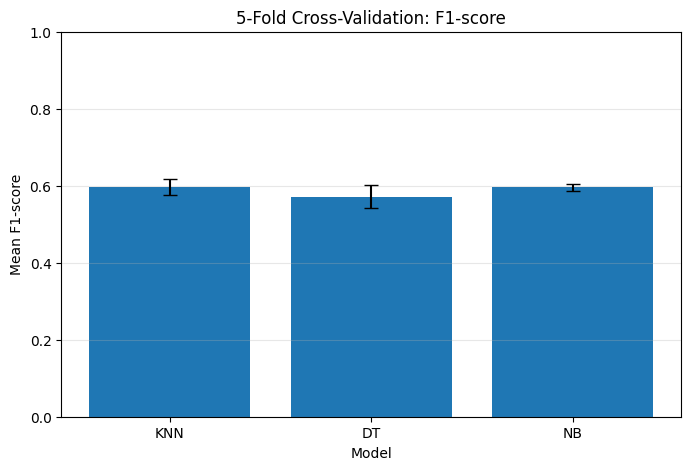

In [153]:
plt.figure(figsize=(8, 5))

plt.bar(
    cv_summary["Model"],
    cv_summary["F1 Mean"],
    yerr=cv_summary["F1 Std"],
    capsize=5
)

plt.title("5-Fold Cross-Validation: F1-score")
plt.xlabel("Model")
plt.ylabel("Mean F1-score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()